# Data preview: Dataset B (Xin, GSE81608) and Dataset C (Muraro, GSE85241)
In this notebook I examine the two additional human pancreas datasets named in the proposal and in Step F2 of
`data_preview.ipynb`: **Dataset B = Xin et al. (GSE81608, Fluidigm C1 / SMARTer, full-length)** and **Dataset C =
Muraro et al. (GSE85241, automated CEL-seq2, 3' UMI)**. Together with Baron (Dataset A, inDrop) they give the
**technology-shift** scenario of E2. The notebook follows the structure of `data_preview.ipynb`: first what the GEO
SOFT files contain, then a full inspection of each dataset (overview → integrity / missing values → labels →
per-cell QC → gene-level behaviour → markers / ambient RNA → global structure → summary → preprocessing proposal),
and finally a short cross-dataset comparison with Baron. No model is fitted here.

## 0. Shared setup
Imports, paths, plot style and a few helper functions used by both dataset parts. The helpers are the same
computations as the inline code in `data_preview.ipynb` §1.2–1.7, only parameterised so that B and C run the
identical check.

In [ ]:
# --- Imports ---------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # silence pandas/numexpr version chatter

from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
import GEOparse
GEOparse.set_verbosity("ERROR")   # otherwise one DEBUG line per GSM (1,600 for Xin)

# --- Reproducibility ------------------------------------------------------------
# PCA (randomised solver) and silhouette subsampling are the only random steps.
SEED = 0
np.random.seed(SEED)

# --- Paths ------------------------------------------------------------------
# Raw files follow the project pattern data/raw/<name>_<GSE>/ (data/ is git-ignored). All of them are the
# official GEO/NCBI files; see the per-dataset §0 cells for what each one is.
PROJECT    = Path("/home/professor/cell-type-annotaion-benchmark")
RAW        = PROJECT / "data" / "raw"
INTERIM    = PROJECT / "data" / "interim"
XIN_DIR    = RAW / "xin_GSE81608"
MURARO_DIR = RAW / "muraro_GSE85241"
XIN_SOFT, XIN_RPKM = XIN_DIR / "GSE81608_family.soft.gz", XIN_DIR / "GSE81608_human_islets_rpkm.txt.gz"
MUR_SOFT = MURARO_DIR / "GSE85241_family.soft.gz"
MUR_CSV  = MURARO_DIR / "GSE85241_cellsystems_dataset_4donors_updated.csv.gz"
MUR_BC   = MURARO_DIR / "GSE85241_cel-seq_barcodes.csv.gz"
# Muraro author cell-type labels are not on GEO: they come from Bioconductor ExperimentHub EH2693
# (scRNAseq::MuraroPancreasData colData, https://experimenthub.bioconductor.org/fetch/2709), exported to CSV.
MUR_LABELS = RAW / "muraro_scRNAseq_EH2693" / "coldata.csv"
GENE_INFO = RAW / "ncbi_gene_info" / "Homo_sapiens.gene_info.gz"   # NCBI Entrez ID -> symbol table (for Xin)
XIN_H5, MURARO_H5, BARON_H5 = INTERIM / "xin_human.h5ad", INTERIM / "muraro_human.h5ad", INTERIM / "baron_human.h5ad"
for p in (XIN_SOFT, XIN_RPKM, MUR_SOFT, MUR_CSV, MUR_BC, GENE_INFO):
    assert p.exists(), f"{p} missing: download it from GEO / NCBI (see the §0 cells of each dataset)"
assert MUR_LABELS.exists(), f"{MUR_LABELS} missing: see data/raw/muraro_scRNAseq_EH2693/README.txt"

# --- Plot style (identical to data_preview.ipynb) -------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "legend.frameon": False,
})
from importlib.metadata import version
print("scanpy", version("scanpy"), "| anndata", version("anndata"), "| scikit-learn", version("scikit-learn"),
      "| GEOparse", version("GEOparse"))

scanpy 1.12.4 | anndata 0.13.4 | scikit-learn 1.7.1 | GEOparse 2.0.4


In [ ]:
# --- Helper functions shared by Dataset B and Dataset C ----------------------------

def soft_samples(gse):
    """One row per GSM: title/description/platform plus every 'key: value' characteristic as its own column."""
    rows = {}
    for gsm_id, gsm in gse.gsms.items():
        m = gsm.metadata
        r = {"title": m["title"][0], "description": "; ".join(m.get("description", [])),
             "platform": m["platform_id"][0], "source": m["source_name_ch1"][0],
             "table_rows": gsm.table.shape[0], "supplementary_file": m.get("supplementary_file_1", ["NONE"])[0]}
        for ch in m.get("characteristics_ch1", []):
            k, _, v = ch.partition(":")
            r[k.strip()] = v.strip()
        rows[gsm_id] = r
    return pd.DataFrame.from_dict(rows, orient="index")


def integrity_checks(adata, integer_expected):
    """Same list as data_preview.ipynb §1.2 (non-integer check only where the values are supposed to be counts)."""
    X = adata.X
    checks = {
        "NaN/Inf in matrix":         int((~np.isfinite(X.data)).sum()),
        "negative values":           int((X.data < 0).sum()),
        "non-integer values":        int((X.data != np.round(X.data)).sum()),
        "NaN cells in obs":          int(adata.obs.isna().sum().sum()),
        "NaN cells in var":          int(adata.var.isna().sum().sum()),
        "duplicated cell IDs":       int(adata.obs_names.duplicated().sum()),
        "duplicated gene names":     int(adata.var_names.duplicated().sum()),
        "cells with zero total":     int((np.asarray(X.sum(1)).ravel() == 0).sum()),
        "genes detected in 0 cells": int((np.asarray((X > 0).sum(0)).ravel() == 0).sum()),
    }
    s = pd.Series(checks, name="count").to_frame()
    s["expected"] = ["0", "0", "0" if integer_expected else "n/a (not counts)", "0", "0", "0", "0", "0", "-"]
    return s


def gene_vec(adata, symbol, layer=None):
    """Dense vector of one gene, looked up by symbol (var['symbol'])."""
    j = np.flatnonzero(adata.var["symbol"].values == symbol)
    assert len(j) == 1, (symbol, len(j))
    M = adata.X if layer is None else adata.layers[layer]
    return np.asarray(M[:, j[0]].todense()).ravel()


def gene_level(adata, unit):
    """Detection counts, top genes and mean/variance per gene (data_preview.ipynb §1.5)."""
    X = adata.X
    n_cells_expr = np.asarray((X > 0).sum(0)).ravel()
    gene_tot = np.asarray(X.sum(0)).ravel()
    mean = np.asarray(X.mean(0)).ravel()
    var = np.asarray(X.multiply(X).mean(0)).ravel() - mean ** 2
    print("Genes detected in at most k cells:")
    for k in [0, 2, 9, 19, 49]:
        print(f"  <= {k:>2} cells: {(n_cells_expr <= k).sum():>5}  ({100 * (n_cells_expr <= k).mean():.1f}%)")
    top = pd.Series(gene_tot / gene_tot.sum() * 100, index=adata.var["symbol"].values).sort_values(ascending=False).head(15)
    print(f"\nTop-15 genes by share of all {unit} (%):"); print(top.round(2).to_string())
    return n_cells_expr, mean, var


def plot_gene_level(n_cells_expr, mean, var, n_obs, unit):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    k = mean > 0
    axes[0].scatter(mean[k], var[k], s=2, alpha=0.3, color=PALETTE[0], linewidths=0)
    xx = np.logspace(np.log10(mean[k].min()), np.log10(mean[k].max()), 50)
    axes[0].plot(xx, xx, color=INK, lw=1, ls="--", label="Poisson: var = mean")
    slope, icpt = np.polyfit(np.log10(mean[k]), np.log10(var[k]), 1)
    axes[0].plot(xx, 10 ** icpt * xx ** slope, color=PALETTE[1], lw=1.5, label=f"fit: slope {slope:.2f}")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel(f"mean {unit} per cell"); axes[0].set_ylabel("variance"); axes[0].legend(fontsize=8)
    axes[0].set_title(f"(a) Variance grows with the mean ({unit})")
    det = n_cells_expr / n_obs * 100
    axes[1].hist(det[det > 0], bins=np.logspace(np.log10(det[det > 0].min()), 2, 50), color=PALETTE[0],
                 edgecolor="#fcfcfb", lw=0.5)
    axes[1].set_xscale("log"); axes[1].set_xlabel("% of cells in which the gene is detected (log)")
    axes[1].set_ylabel("genes"); axes[1].set_title("(b) Most genes are detected in few cells")
    fig.tight_layout(); plt.show()
    return slope


def detection_heatmap(adata, genes, labels, row_order, title, layer=None):
    """% of cells with value > 0 for each marker, per label (data_preview.ipynb §1.6)."""
    genes = [g for g in dict.fromkeys(genes) if (adata.var["symbol"] == g).sum() == 1]
    detect = pd.DataFrame({g: gene_vec(adata, g, layer) > 0 for g in genes},
                          index=adata.obs_names).groupby(np.asarray(labels)).mean().loc[row_order] * 100
    fig, ax = plt.subplots(figsize=(0.45 * len(genes) + 2.5, 0.38 * len(row_order) + 1.6))
    im = ax.imshow(detect.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(genes)), genes, rotation=45, ha="right"); ax.set_yticks(range(len(row_order)), row_order)
    ax.grid(False)
    for i in range(detect.shape[0]):
        for j in range(detect.shape[1]):
            v = detect.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else INK)
    fig.colorbar(im, ax=ax, label="% of cells with value > 0", shrink=0.8)
    ax.set_title(title); fig.tight_layout(); plt.show()
    return detect


def throwaway_pca(adata):
    """Inspection-only pipeline from data_preview.ipynb §1.7: normalise to 10k -> log1p -> 2,000 HVGs -> z-score -> PCA."""
    tmp = adata.copy()
    sc.pp.normalize_total(tmp, target_sum=1e4)
    sc.pp.log1p(tmp)
    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    tmp = tmp[:, tmp.var.highly_variable].copy()
    sc.pp.scale(tmp, max_value=10)
    sc.tl.pca(tmp, n_comps=50, random_state=SEED)
    evr = tmp.uns["pca"]["variance_ratio"]
    print("Explained variance, PC1..PC10 (%):", np.round(100 * evr[:10], 1))
    print(f"Cumulative variance in 20 / 50 PCs: {100 * evr[:20].sum():.1f}% / {100 * evr.sum():.1f}%")
    loadings = pd.DataFrame(tmp.varm["PCs"][:, :2], index=tmp.var_names, columns=["PC1", "PC2"])
    return tmp.obsm["X_pca"], evr, loadings


def scatter_groups(ax, P, groups, colors, title, perm):
    g = np.asarray(groups)[perm]; Pp = P[perm]
    for name, c in colors.items():
        s = g == name
        ax.scatter(Pp[s, 0], Pp[s, 1], s=3, alpha=0.6, color=c, label=f"{name}", linewidths=0)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(markerscale=4, fontsize=7)


# Pancreas label hierarchy (top level), shared with Baron (data_preview.ipynb §1.3). Covers the label
# vocabularies of all three datasets after lower-casing.
LINEAGE = {
    "alpha": "endocrine", "beta": "endocrine", "delta": "endocrine", "gamma": "endocrine", "pp": "endocrine",
    "epsilon": "endocrine", "acinar": "exocrine", "ductal": "exocrine",
    "activated_stellate": "stromal", "quiescent_stellate": "stromal", "mesenchymal": "stromal",
    "endothelial": "stromal", "schwann": "stromal", "macrophage": "immune", "mast": "immune", "t_cell": "immune",
    "unassigned": "unassigned",
}
LINEAGE_ORDER = ["endocrine", "exocrine", "stromal", "immune"]
LINEAGE_COLOR = dict(zip(LINEAGE_ORDER, PALETTE[:4])) | {"unassigned": MUTED}

---
# Dataset B — Xin et al. (GSE81608, human islets, Fluidigm C1 SMARTer)

## B.0 What is in the SOFT file, and conversion
The SOFT file was copied (not moved) from `~/Downloads/proj_data/` to `data/raw/xin_GSE81608/`.

In [ ]:
gse_b = GEOparse.get_GEO(filepath=str(XIN_SOFT))
print("GEO accession:", gse_b.name, "|", gse_b.metadata["title"][0])
print("Platforms:", list(gse_b.gpls), "| number of samples (GSM):", len(gse_b.gsms))
print("Series supplementary files:", *gse_b.metadata["supplementary_file"], sep="\n  ")

meta_b = soft_samples(gse_b)
print("\nGSM tables with rows:", int((meta_b.table_rows > 0).sum()), "| GSM supplementary files:",
      meta_b.supplementary_file.value_counts().to_dict())
print("Characteristic keys:", [c for c in meta_b.columns if c not in
      ("title", "description", "platform", "source", "table_rows", "supplementary_file")])
meta_b.head(3)

GEO accession: GSE81608 | RNA Sequencing of Single Human Islet Cells Reveals Type 2 Diabetes Genes
Platforms: ['GPL16791'] | number of samples (GSM): 1600
Series supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE81nnn/GSE81608/suppl/GSE81608_human_islets_rpkm.txt.gz

GSM tables with rows: 0 | GSM supplementary files: {'NONE': 1600}
Characteristic keys: ['tissue', 'donor id', 'condition', 'age', 'ethnicity', 'gender', 'cell subtype']


,title,description,platform,source,table_rows,supplementary_file,tissue,donor id,condition,age,ethnicity,gender,cell subtype
GSM2157899,Pancreatic islet cell sample 1,,GPL16791,Pancreatic islets,0,NONE,Pancreatic islets,Non T2D 1,non-diabetic,23,AA,M,beta
GSM2157900,Pancreatic islet cell sample 2,,GPL16791,Pancreatic islets,0,NONE,Pancreatic islets,Non T2D 1,non-diabetic,23,AA,M,beta
GSM2157901,Pancreatic islet cell sample 3,,GPL16791,Pancreatic islets,0,NONE,Pancreatic islets,Non T2D 1,non-diabetic,23,AA,M,beta


**What the SOFT file contains.** As with Baron, there is **no expression data** in it: all 1,600 GSM tables are
`(0, 0)` and no GSM has a supplementary file. Unlike Baron, though, every GSM here is **one cell** (Fluidigm C1, one
SRA run per cell), and its characteristics carry the full per-cell metadata: **donor ID, condition (T2D /
non-diabetic), age, sex, ethnicity and the author cell-type label (`cell subtype`)**. So the labels come straight
from GEO and need no curated object. Platform GPL16791 = Illumina HiSeq 2500.

The expression matrix is the single series supplementary file `GSE81608_human_islets_rpkm.txt.gz` (37 MB),
downloaded from the GEO FTP site into `data/raw/xin_GSE81608/`. Two things to know about it:
* it holds **RPKM values, not counts** (SOFT `data_processing`: "tab-delimited text files include RPKM values for
  each sample"; reads mapped to GRCh37 with CLC Genomics Workbench). Raw counts are only obtainable by re-processing
  the SRA reads;
* genes are identified by **NCBI Entrez Gene IDs**, without symbols. They are mapped to symbols with the NCBI
  `Homo_sapiens.gene_info.gz` table (also downloaded, into `data/raw/ncbi_gene_info/`).

The conversion below replaces the `export_sce.R` → `build_h5ad.py` route used for Baron (there is no `.rds` here),
but produces the same layout: cells × genes, `X` = the deposited assay, the same assay also kept as a layer, saved
to `data/interim/xin_human.h5ad`. Columns `Sample_N` of the matrix are matched to the GSM titles
("Pancreatic islet cell sample N"), and the match is checked to be one-to-one.

In [ ]:
def build_xin():
    """GEO RPKM table (genes x cells, Entrez IDs) + SOFT characteristics -> AnnData (cells x genes)."""
    rpkm = pd.read_csv(XIN_RPKM, sep="\t", index_col=0)                     # 39,851 genes x 1,600 cells
    print("RPKM table (genes x cells):", rpkm.shape)

    # Cells: matrix column 'Sample_N' <-> GSM title 'Pancreatic islet cell sample N'.
    m = meta_b.copy()
    m["sample_no"] = m["title"].str.extract(r"sample (\d+)$", expand=False).astype(int)
    col_no = rpkm.columns.str.replace("Sample_", "", regex=False).astype(int)
    assert m.sample_no.is_unique and set(col_no) == set(m.sample_no), "matrix columns and GSMs do not match 1:1"
    obs = (m.rename_axis("gsm").reset_index().set_index("sample_no").loc[col_no]
             .rename(columns={"cell subtype": "cell_type1", "donor id": "donor"}))
    obs.index = rpkm.columns.astype(str); obs.index.name = "cell_id"
    obs = obs[["gsm", "cell_type1", "donor", "condition", "age", "gender", "ethnicity", "tissue", "platform"]]
    obs["age"] = obs["age"].astype(int)

    # Genes: Entrez Gene IDs -> official symbol via NCBI gene_info; IDs no longer in gene_info keep 'Entrez_<id>'.
    gi = pd.read_csv(GENE_INFO, sep="\t", usecols=["GeneID", "Symbol", "chromosome", "type_of_gene"]).set_index("GeneID")
    var = pd.DataFrame({"entrez_id": rpkm.index.astype(int)})
    var = var.join(gi, on="entrez_id")
    var["symbol"] = var["Symbol"].fillna("Entrez_" + var["entrez_id"].astype(str))
    var["mapped"] = var["Symbol"].notna()
    var = var.drop(columns="Symbol").rename(columns={"type_of_gene": "gene_type"})
    var[["chromosome", "gene_type"]] = var[["chromosome", "gene_type"]].fillna("unknown")
    var.index = var["symbol"].astype(str); var.index.name = "gene_id"

    X = sp.csr_matrix(rpkm.values.T, dtype="float32")
    assert np.allclose(np.asarray(X.sum(1)).ravel(), rpkm.sum(axis=0).values, rtol=1e-4), "conversion mismatch"
    print("Row sums of X match the GEO table column sums -> conversion is lossless (float32)")
    a = ad.AnnData(X=X, obs=obs, var=var, layers={"rpkm": X.copy()})
    a.uns["X_source_assay"] = "rpkm"
    a.uns["source_files"] = [str(XIN_SOFT), str(XIN_RPKM), str(GENE_INFO)]
    a.write_h5ad(XIN_H5, compression="gzip")
    print(f"-> {XIN_H5}: {a.n_obs} cells x {a.n_vars} genes")
    return a

xin = build_xin()

RPKM table (genes x cells): (39851, 1600)


Row sums of X match the GEO table column sums -> conversion is lossless (float32)


-> /home/professor/cell-type-annotaion-benchmark/data/interim/xin_human.h5ad: 1600 cells x 39851 genes


## B.1 Overview of the Xin (GSE81608) object

In [ ]:
print(xin)
print("\nX is assay:", xin.uns["X_source_assay"], "| dtype:", xin.X.dtype, "| sparse:", sp.issparse(xin.X))
print(f"Sparsity (fraction of zeros): {1 - xin.X.nnz / np.prod(xin.shape):.3f}")
print("Value range:", float(xin.X.min()), "-", round(float(xin.X.max()), 1),
      "| per-cell total RPKM:", pd.Series(np.asarray(xin.X.sum(1)).ravel()).describe()[["min", "50%", "max"]].round(0).to_dict())
xin.obs.head(3)

AnnData object with n_obs × n_vars = 1600 × 39851
    obs: 'gsm', 'cell_type1', 'donor', 'condition', 'age', 'gender', 'ethnicity', 'tissue', 'platform'
    var: 'entrez_id', 'chromosome', 'gene_type', 'symbol', 'mapped'
    uns: 'X_source_assay', 'source_files'
    layers: 'rpkm', None (.X)

X is assay: rpkm | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.856
Value range: 0.0 - 443598.2 | per-cell total RPKM: {'min': 308756.0, '50%': 538526.0, 'max': 868112.0}


,gsm,cell_type1,donor,condition,age,gender,ethnicity,tissue,platform
cell_id,,,,,,,,,
Sample_1,GSM2157899,beta,Non T2D 1,non-diabetic,23,M,AA,Pancreatic islets,GPL16791
Sample_2,GSM2157900,beta,Non T2D 1,non-diabetic,23,M,AA,Pancreatic islets,GPL16791
Sample_3,GSM2157901,beta,Non T2D 1,non-diabetic,23,M,AA,Pancreatic islets,GPL16791


**What we have:** 1,600 cells × 39,851 genes, a single assay:

* `rpkm`: reads per kilobase per million, as deposited. Per-cell totals range from 309k to 868k, so it is neither
  counts nor a fixed-sum normalisation (RPKM per cell does not sum to a constant), and it is **gene-length
  normalised**. This is the same situation as Camp in `data_preview.ipynb` (FPKM-like only): the proposal's
  "library-size normalisation followed by log(1+x)" cannot be applied to raw counts for this dataset.

About 86% of entries are zero (less sparse than Baron's 91%: full-length C1 data detect more genes per cell).

`obs` has 9 columns, all from the SOFT file: GSM accession, `cell_type1` (author label), donor, condition, age,
gender, ethnicity, and two constant columns (tissue, platform). There are no pre-computed QC columns.

**Where the expression values live.** `xin` is an AnnData object: three linked parts, of which only two are tables
that get printed. `xin.X` is the expression matrix itself, one row per cell and one column per gene (for Xin: RPKM as deposited, not counts). It is
stored *sparse* (only the non-zero entries and their positions) because most entries are zero, so it is never shown as
a table. `xin.obs` is one row per cell (labels, donor, QC: the table above), and `xin.var` is one row per gene: its index,
`xin.var_names`, holds the gene names, i.e. the column names of `X`. Neither contains expression values. `xin.layers`
holds other versions of the same matrix (`rpkm`, identical to `X`). The expression of a gene in a cell is read by slicing `X` with cell
IDs and gene names; below, one example cell per major type against the marker gene of each type.

In [ ]:
# Where the expression values live: xin.X is the cells x genes matrix; its rows are named by xin.obs_names (cells)
# and its columns by xin.var_names (genes). xin.obs / xin.var describe those rows / columns and hold no expression.
print("X:", type(xin.X).__name__, xin.X.shape, "| holds:", xin.uns["X_source_assay"],
      "| other versions in layers:", [k for k in xin.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(xin.var_names[:5]), "...")
print(f"Stored non-zero values: {xin.X.nnz:,} of {np.prod(xin.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['alpha', 'beta', 'delta', 'PP']
ex_genes = ['GCG', 'INS', 'SST', 'PPY']
ex_cells = [xin.obs_names[xin.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = xin[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", xin.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (1600, 39851) | holds: rpkm | other versions in layers: ['rpkm']
Gene names = column names of X (var_names): ['A1BG', 'A2M', 'Entrez_3', 'NAT1', 'NAT2'] ...
Stored non-zero values: 9,162,358 of 63,761,600 entries


gene_id,cell_type1,GCG,INS,SST,PPY
cell_id,,,,,
Sample_208,alpha,49790.246094,22.468201,0.000000,0.000000
Sample_1,beta,278.692596,24994.855469,0.000000,0.000000
Sample_585,delta,431.861603,0.000000,44024.585938,91.888199
Sample_613,PP,90.508400,4.330000,13.236700,158652.828125


## B.2 Data integrity and missing values
Same five questions as for Baron: (1) NaN/Inf, (2) negative or non-integer values, (3) duplicated cell or gene
names, (4) constant metadata columns, (5) genes never detected. For RPKM "non-integer" is expected and is not a
defect.

In [ ]:
display(integrity_checks(xin, integer_expected=False))
constant_cols = [c for c in xin.obs.columns if xin.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
print(f"Entrez IDs without a current symbol in NCBI gene_info: {(~xin.var.mapped).sum()} "
      f"({(~xin.var.mapped).mean():.1%}); of these detected in >= 1 cell: "
      f"{int((np.asarray((xin.X[:, (~xin.var.mapped).values] > 0).sum(0)).ravel() > 0).sum())}")

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,9161555,n/a (not counts)
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,5962,-


2 constant obs columns (no information): ['tissue', 'platform']
Entrez IDs without a current symbol in NCBI gene_info: 1864 (4.7%); of these detected in >= 1 cell: 1664


In [ ]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names_b = xin.var["symbol"]
mt_b = (xin.var["chromosome"] == "MT").values
print("genes on chrM (MT-...):  ", int(mt_b.sum()), list(names_b[mt_b][:6]))
rib_b = names_b.str.match(r"^RP[LS]\d")
print("RPL/RPS ribosomal names:", int(rib_b.sum()), "| of which protein-coding:",
      int((rib_b & (xin.var.gene_type == "protein-coding")).sum()), "(the rest are RPL/RPS pseudogenes)")
print("names starting 'ERCC':  ", list(names_b[names_b.str.startswith("ERCC")][:8]))
print("gene types:", xin.var["gene_type"].value_counts().head(6).to_dict())

genes on chrM (MT-...):   37 ['ATP6', 'ATP8', 'TRNC', 'COX1', 'COX2', 'COX3']
RPL/RPS ribosomal names: 1949 | of which protein-coding: 97 (the rest are RPL/RPS pseudogenes)
names starting 'ERCC':   ['ERCC8', 'ERCC1', 'ERCC2', 'ERCC3', 'ERCC4', 'ERCC5', 'ERCC6', 'ERCC6L']
gene types: {'protein-coding': 19204, 'pseudo': 11872, 'ncRNA': 5646, 'unknown': 1868, 'tRNA': 435, 'snoRNA': 389}


**Integrity results**
* **No missing values.** No NaN/Inf, no negative values, no duplicated cell or gene names, no empty cells. The
  RPKM values are non-integer by construction. The conversion is lossless (row sums equal the GEO column sums).
* **5,962 genes (15%) are never detected.** As for Baron, these are dead features, not missing data.
* **1,864 Entrez IDs (4.7%) have no current symbol** in NCBI `gene_info` (discontinued or replaced IDs from the
  2016 annotation), and 1,664 of them are detected in at least one cell. They are kept under the name
  `Entrez_<id>` for now. They will drop out at the gene-intersection step anyway. Recovering them via NCBI
  `gene_history` is possible but not worth it for the pilot.
* **Mitochondrial genes are present (37 on chrM)**, unlike Baron. Note that NCBI names them `COX1`, `ATP6`, `ND4`,
  … **without the `MT-` prefix**, so a `startswith("MT-")` rule would silently find none. Here they are found
  through the chromosome column.
* **Many more features than Baron (39,851 vs 20,125):** about 11,900 pseudogenes and 5,600 ncRNAs. 1,949 names
  match `RPL*/RPS*`, but only 97 are protein-coding, and the rest are ribosomal pseudogenes. These extra features
  matter in B.7 (they enter the HVG set) and disappear when intersecting with the other datasets.
* `ERCC1…ERCC8` are again real DNA-repair genes; there are no spike-ins.

## B.3 Cell-type labels: what are we classifying?

In [ ]:
ct_b = xin.obs["cell_type1"].astype(str)
donor_b = xin.obs["donor"].astype(str)
cond_b = xin.obs["condition"].astype(str)
counts_b = ct_b.value_counts()
display(pd.DataFrame({"n_cells": counts_b, "fraction_%": (100 * counts_b / counts_b.sum()).round(2)}))
print(f"{ct_b.nunique()} classes; imbalance ratio largest/smallest = {counts_b.max() / counts_b.min():.0f}x")
print(f"{donor_b.nunique()} donors: {(xin.obs.groupby('donor').condition.first() == 'T2D').sum()} T2D, "
      f"{(xin.obs.groupby('donor').condition.first() == 'non-diabetic').sum()} non-diabetic; "
      f"cells per donor {donor_b.value_counts().min()}-{donor_b.value_counts().max()}")

# Donor order: non-diabetic first, then T2D, each by name number.
donor_meta_b = (xin.obs.groupby("donor", observed=True)[["condition", "age", "gender", "ethnicity"]].first()
                .assign(n_cells=donor_b.value_counts()))
donor_meta_b["_k"] = donor_meta_b.index.str.extract(r"(\d+)$", expand=False).astype(int).values
DONOR_ORDER_B = donor_meta_b.sort_values(["condition", "_k"], ascending=[True, True]).index.tolist()
xt_b = pd.crosstab(ct_b, donor_b).loc[counts_b.index, DONOR_ORDER_B]
display(xt_b.style.background_gradient(cmap="Blues", axis=None))
display(pd.crosstab(ct_b, cond_b, margins=True))

,n_cells,fraction_%
cell_type1,,
alpha,946,59.12
beta,503,31.44
PP,93,5.81
delta,58,3.62


4 classes; imbalance ratio largest/smallest = 16x
18 donors: 6 T2D, 12 non-diabetic; cells per donor 24-306


donor,T2D 1,T2D 2,T2D 3,T2D 4,T2D 5,T2D 6,Non T2D 1,Non T2D 2,Non T2D 3,Non T2D 4,Non T2D 5,Non T2D 6,Non T2D 7,Non T2D 8,Non T2D 9,Non T2D 10,Non T2D 11,Non T2D 12
cell_type1,,,,,,,,,,,,,,,,,,
alpha,39,50,33,152,161,134,56,4,29,15,26,38,8,14,26,20,49,92
beta,12,18,29,144,12,81,13,13,10,11,24,7,17,17,7,26,12,50
PP,36,10,3,2,2,1,3,5,2,5,2,1,4,11,4,1,1,0
delta,4,5,4,8,1,8,5,2,3,0,5,4,0,3,1,2,1,2


condition,T2D,non-diabetic,All
cell_type1,,,
PP,54,39,93
alpha,569,377,946
beta,296,207,503
delta,30,28,58
All,949,651,1600


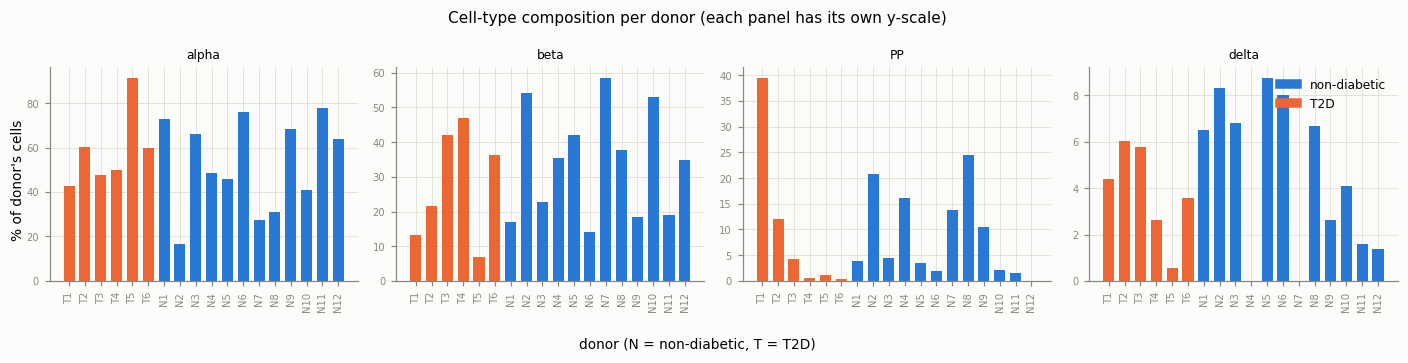

donor,T2D 1,T2D 2,T2D 3,T2D 4,T2D 5,T2D 6,Non T2D 1,Non T2D 2,Non T2D 3,Non T2D 4,Non T2D 5,Non T2D 6,Non T2D 7,Non T2D 8,Non T2D 9,Non T2D 10,Non T2D 11,Non T2D 12
condition,T2D,T2D,T2D,T2D,T2D,T2D,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic,non-diabetic
age,57,37,55,41,42,51,23,32,23,56,27,68,29,60,24,43,31,56
gender,M,F,F,F,M,M,M,F,F,F,M,M,M,M,F,M,F,M
ethnicity,AA,C,C,H,C,H,AA,C,C,C,AA,C,C,AI,C,C,H,AA
n_cells,91,83,69,306,176,224,77,24,44,31,57,50,29,45,38,49,63,144


In [ ]:
# Cell-type composition per donor (fractions); small multiples per class, bars coloured by condition.
COND_COLOR = {"non-diabetic": PALETTE[0], "T2D": PALETTE[1]}
frac_b = xt_b.div(xt_b.sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, t in zip(axes, frac_b.index):
    ax.bar(range(len(DONOR_ORDER_B)), frac_b.loc[t].values, width=0.7,
           color=[COND_COLOR[donor_meta_b.loc[d, "condition"]] for d in DONOR_ORDER_B])
    ax.set_title(t, fontsize=8)
    ax.set_xticks(range(len(DONOR_ORDER_B)), [d.replace("Non T2D ", "N").replace("T2D ", "T") for d in DONOR_ORDER_B],
                  rotation=90)
    ax.tick_params(labelsize=6.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COND_COLOR.values()]
axes[-1].legend(handles, COND_COLOR.keys(), fontsize=8, loc="upper right")
fig.supxlabel("donor (N = non-diabetic, T = T2D)", fontsize=9)
fig.supylabel("% of donor's cells", fontsize=9)
fig.suptitle("Cell-type composition per donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()
display(donor_meta_b.drop(columns="_k").loc[DONOR_ORDER_B].T)

**Label observations**
* **Only 4 classes, all endocrine:** alpha 946 (59%), beta 503 (31%), PP 93 and delta 58 (imbalance 16×). There
  are no exocrine, stromal or immune cells and no epsilon cells: the study analysed islet preparations and
  deposited only the four main islet types. `PP` is the same type Baron calls `gamma`. **Alpha cells are the
  majority here, whereas beta cells were in Baron**, so the class prior shifts between A and B.
* **No class is below 20 cells**, so the minimum-class-size question from `data_preview.ipynb` (Step B) does not
  arise inside Xin.
* **18 donors (12 non-diabetic, 6 T2D)**, but very unbalanced: 24–306 cells per donor. A single donor (T2D 4)
  contributes 19% of all cells, and the T2D group has more cells (949) than the non-diabetic group (651).
* **Composition varies a lot between donors:** the alpha fraction ranges from about 17% (Non T2D 2) to about 91%
  (T2D 5), PP cells make up about 40% of T2D 1 but are almost absent in several donors, and some donors have no
  delta cells at all. As in Baron, a donor-wise split shifts the class prior as well as the expression.
* **New shift axis: disease state.** Xin adds T2D vs non-diabetic donors (all four types in both groups). A
  "train on non-diabetic, test on T2D" split is a biological-condition shift with the same protocol.

## B.4 Per-cell quality metrics: detected genes, total RPKM, mitochondrial share
For RPKM data the per-cell total is **not** a library size (it is the sum of length- and depth-normalised values),
so the depth axis of Baron's QC is replaced by the number of detected genes; total RPKM is shown for completeness.

In [ ]:
X_b = xin.X
TYPE_COLOR_B = dict(zip(["alpha", "beta", "delta", "PP"], PALETTE[:4]))
DONOR_COND_B = donor_b.map(donor_meta_b["condition"])
tot_b = np.asarray(X_b.sum(1)).ravel()
qc_b = pd.DataFrame({
    "total_rpkm": tot_b,
    "n_genes": np.asarray((X_b > 0).sum(1)).ravel(),
    "pct_mt_rpkm": 100 * np.asarray(X_b[:, mt_b].sum(1)).ravel() / tot_b,       # share of RPKM on chrM genes
    "top_gene_frac": np.asarray(X_b.max(1).todense()).ravel() / tot_b,           # share of the cell's RPKM in its top gene
    "cell_type": ct_b.values, "donor": donor_b.values, "condition": cond_b.values,
}, index=xin.obs_names)
display(qc_b[["total_rpkm", "n_genes", "pct_mt_rpkm", "top_gene_frac"]].describe().round(3).T)

,count,mean,std,min,25%,50%,75%,max
total_rpkm,1600.0,540077.625,63361.637,308755.969,495631.930,538526.156,581134.641,868112.500
n_genes,1600.0,5726.474,1148.891,2406.000,4910.000,5687.500,6448.000,11142.000
pct_mt_rpkm,1600.0,18.939,9.407,1.892,11.021,16.585,26.276,45.408
top_gene_frac,1600.0,0.269,0.147,0.031,0.142,0.252,0.391,0.669


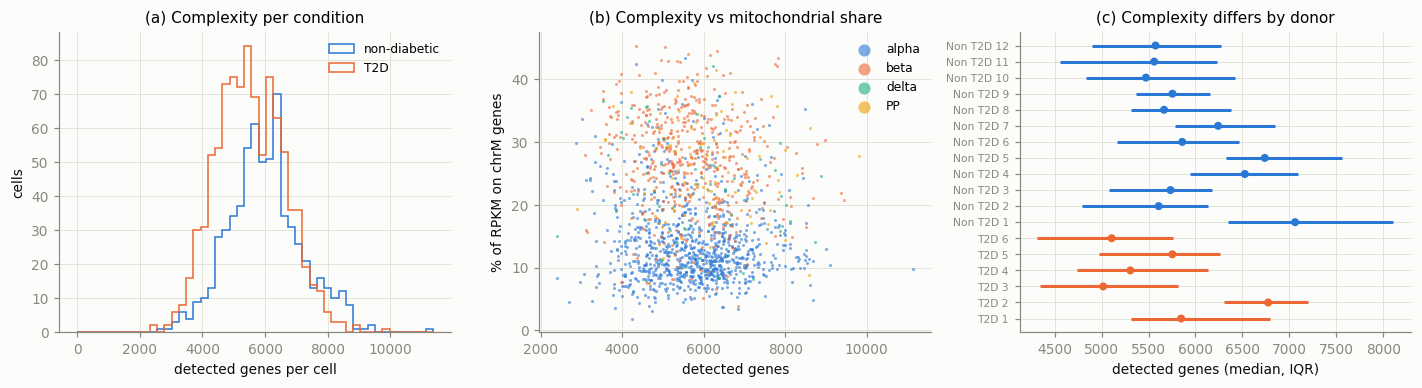

Minimum detected genes in any cell: 2406 | cells < 1,000 / < 2,000 genes: 0 / 0
Cells with > 10% / > 20% RPKM on chrM: 1294 / 653
Median detected genes / %MT / top-gene fraction by type and by condition:
           n_genes  pct_mt_rpkm  top_gene_frac
cell_type                                     
PP          6075.0    24.733999          0.172
alpha       5717.5    12.155000          0.364
beta        5581.0    27.447001          0.117
delta       5834.5    22.517000          0.242
              n_genes  pct_mt_rpkm  top_gene_frac
condition                                        
T2D            5491.0       16.513          0.271
non-diabetic   5965.0       16.847          0.229


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) detected genes per condition
bins = np.linspace(0, qc_b.n_genes.max() * 1.02, 50)
for c, col in COND_COLOR.items():
    axes[0].hist(qc_b.loc[qc_b.condition == c, "n_genes"], bins=bins, histtype="step", lw=1.5, color=col, label=c)
axes[0].set_xlabel("detected genes per cell"); axes[0].set_ylabel("cells"); axes[0].set_title("(a) Complexity per condition")
axes[0].legend(fontsize=8)
# (b) detected genes vs %MT, coloured by cell type
for t, col in TYPE_COLOR_B.items():
    s = qc_b.cell_type == t
    axes[1].scatter(qc_b.n_genes[s], qc_b.pct_mt_rpkm[s], s=4, alpha=0.6, color=col, label=t, linewidths=0)
axes[1].set_xlabel("detected genes"); axes[1].set_ylabel("% of RPKM on chrM genes")
axes[1].set_title("(b) Complexity vs mitochondrial share"); axes[1].legend(markerscale=4, fontsize=8)
# (c) detected genes per donor (median and IQR), donors ordered as in B.3
g = qc_b.groupby("donor")["n_genes"]
med, q1, q3 = g.median()[DONOR_ORDER_B], g.quantile(.25)[DONOR_ORDER_B], g.quantile(.75)[DONOR_ORDER_B]
y = np.arange(len(DONOR_ORDER_B)); cols = [COND_COLOR[donor_meta_b.loc[d, "condition"]] for d in DONOR_ORDER_B]
axes[2].hlines(y, q1, q3, color=cols, lw=2); axes[2].scatter(med, y, color=cols, s=18, zorder=3)
axes[2].set_yticks(y, DONOR_ORDER_B, fontsize=7); axes[2].set_xlabel("detected genes (median, IQR)")
axes[2].set_title("(c) Complexity differs by donor")
fig.tight_layout(); plt.show()

print("Minimum detected genes in any cell:", int(qc_b.n_genes.min()), "| cells < 1,000 / < 2,000 genes:",
      int((qc_b.n_genes < 1000).sum()), "/", int((qc_b.n_genes < 2000).sum()))
print("Cells with > 10% / > 20% RPKM on chrM:", int((qc_b.pct_mt_rpkm > 10).sum()), "/", int((qc_b.pct_mt_rpkm > 20).sum()))
print("Median detected genes / %MT / top-gene fraction by type and by condition:")
print(qc_b.groupby("cell_type")[["n_genes", "pct_mt_rpkm", "top_gene_frac"]].median().round(3).to_string())
print(qc_b.groupby("condition")[["n_genes", "pct_mt_rpkm", "top_gene_frac"]].median().round(3).to_string())

**QC observations**
* **The data have already been filtered.** Every cell has ≥ 2,406 detected genes (median 5,688, about 3× Baron's
  1,847). A standard low-quality filter (< 200 or < 500 genes) removes **nothing**, and the distribution in (a)
  has no low-complexity tail. Xin et al. applied their own QC before deposition.
* **Mitochondrial share is high and cannot be used with standard thresholds.** The median share of RPKM on chrM
  genes is 16.6% (up to 45%); 1,294 cells (81%) exceed 10% and 653 (41%) exceed 20%. Part of this is a unit
  effect: RPKM divides by gene length and the mitochondrial genes are short, so their RPKM share is larger than
  their read share. It is also strongly cell-type dependent: the median is 12% in alpha cells but 27% in beta cells (22–25% in
  delta and PP), which is visible as the upper band in (b). A fixed %MT cut-off
  would therefore remove a large, type-biased part of the data. This supports the decision already taken for
  Baron (where MT genes were absent): no %MT filter in the common QC.
* **T2D cells are slightly less complex** (median 5,491 vs 5,965 detected genes, the histogram is shifted left in (a)), and donor
  medians range from about 5,000 to 7,000 genes (c). This is a mild technical/biological donor effect, to keep
  in mind when interpreting a non-diabetic → T2D split.
* **A single hormone dominates many cells:** in a median alpha cell 36% of all RPKM is one gene (GCG), compared
  with 12% for beta cells. This is stronger than in Baron (where it is 10% for alpha), partly because RPKM boosts
  short, highly expressed transcripts. The log transform is again what keeps this from dominating distances.

## B.5 Gene-level behaviour: detection, top genes, mean–variance relationship

In [ ]:
n_expr_b, mean_b, var_b = gene_level(xin, "RPKM")

Genes detected in at most k cells:
  <=  0 cells:  5962  (15.0%)
  <=  2 cells: 10341  (25.9%)
  <=  9 cells: 14811  (37.2%)
  <= 19 cells: 17668  (44.3%)
  <= 49 cells: 21524  (54.0%)

Top-15 genes by share of all RPKM (%):
GCG       22.15
TTR        5.59
INS        3.51
COX1       2.88
COX2       2.83
RNR2       2.16
COX3       1.88
ATP6       1.50
ND4        1.49
CYTB       1.44
PPY        1.21
B2M        1.05
SST        0.96
ND2        0.78
MALAT1     0.76


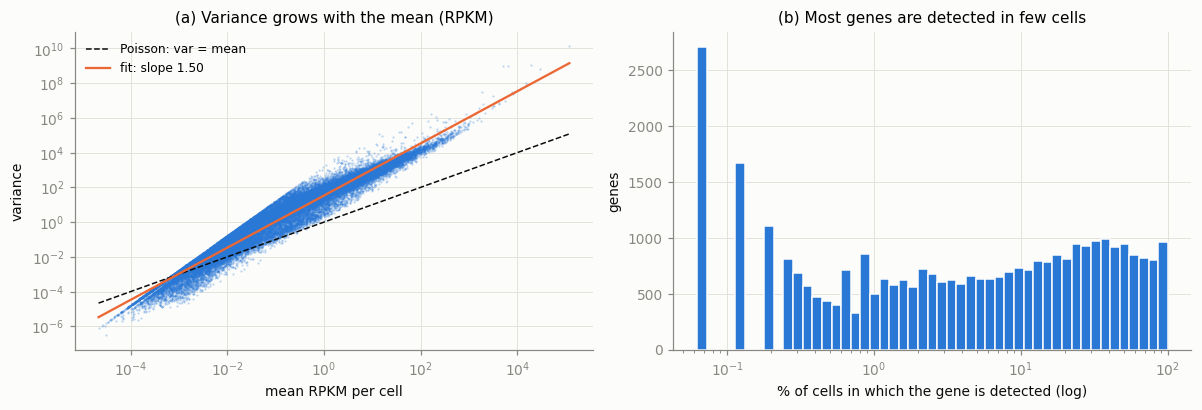

In [ ]:
slope_b = plot_gene_level(n_expr_b, mean_b, var_b, xin.n_obs, "RPKM")

**Gene-level observations**
* **The variance grows much faster than the mean (log-log slope ≈ 1.5, vs ≈ 1.1 for Baron's UMI counts).**
  RPKM from full-length, PCR-amplified C1 data is far from Poisson: amplification noise and the gene-length
  division both add variance at the high end. `log(1 + x)` is even more necessary here than for Baron.
* **GCG alone is 22% of all RPKM in the dataset** (alpha cells are the majority and GCG is short and extremely
  highly expressed), followed by TTR (5.6%) and INS (3.5%). Seven of the top 15 genes are **mitochondrially
  encoded** (COX1–3, RNR2, ATP6, ND4, CYTB), consistent with B.4. After the intersection with Baron (which has no
  MT genes) these will be removed automatically.
* **Feature sparsity is high:** 37% of genes are detected in fewer than 10 cells and 54% in fewer than 50. Much of
  this is the pseudogene/ncRNA tail noted in B.2. The reference-only minimum-detection filter proposed for Baron
  removes them.

## B.6 Labels vs markers, and how "clean" are the markers?
Same marker panel as for Baron (one canonical marker per Baron type, plus a second, independent marker for the four
Xin types: IRX2/ARX for alpha, MAFA for beta, HHEX for delta). Xin only labels four endocrine types, so the
non-endocrine markers test whether other cell types are hidden in the data.

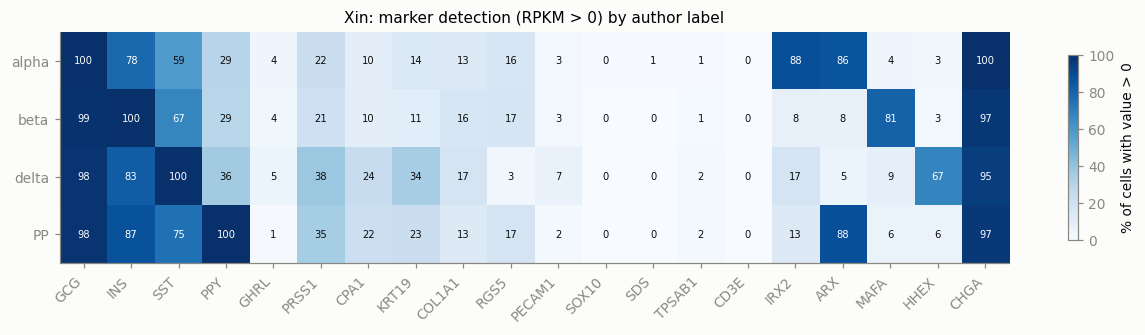

In [ ]:
MARKERS = {   # same panel as data_preview.ipynb §1.6
    "alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY", "epsilon": "GHRL",
    "acinar": "PRSS1", "acinar ": "CPA1", "ductal": "KRT19",
    "activated_stellate": "COL1A1", "quiescent_stellate": "RGS5", "endothelial": "PECAM1",
    "schwann": "SOX10", "macrophage": "SDS", "mast": "TPSAB1", "t_cell": "CD3E",
}
EXTRA_ENDOCRINE = ["IRX2", "ARX", "MAFA", "HHEX", "CHGA"]
order_b = ["alpha", "beta", "delta", "PP"]
detect_b = detection_heatmap(xin, list(MARKERS.values()) + EXTRA_ENDOCRINE, ct_b, order_b,
                             "Xin: marker detection (RPKM > 0) by author label")

In [ ]:
# Hormone purity: which of the four islet hormones dominates each cell, and is a second one almost as high?
HORMONE = {"alpha": "GCG", "beta": "INS", "delta": "SST", "PP": "PPY"}
H = pd.DataFrame({t: np.log1p(gene_vec(xin, g)) for t, g in HORMONE.items()}, index=xin.obs_names)
top_h = H.idxmax(axis=1)
srt = np.sort(H.values, axis=1)
mixed = srt[:, -2] > 0.8 * srt[:, -1]                  # second hormone within 20% of the top one (log scale)
purity_b = pd.DataFrame({
    "n_cells": counts_b[order_b],
    "top hormone = label": [(top_h[ct_b == t] == t).sum() for t in order_b],
    "top hormone != label": [(top_h[ct_b == t] != t).sum() for t in order_b],
    "two hormones high (mixed)": [int(mixed[(ct_b == t).values].sum()) for t in order_b],
})
display(purity_b)
print("Total 'mixed' cells:", int(mixed.sum()), "| label != top hormone:", int((top_h != ct_b).sum()),
      "| union:", int((mixed | (top_h != ct_b).values).sum()))
print("Paper abstract reports 1,492 cells; GEO has", xin.n_obs, "-> difference", xin.n_obs - 1492)

,n_cells,top hormone = label,top hormone != label,two hormones high (mixed)
cell_type1,,,,
alpha,946,946,0,0
beta,503,503,0,10
delta,58,58,0,3
PP,93,93,0,2


Total 'mixed' cells: 15 | label != top hormone: 0 | union: 15
Paper abstract reports 1,492 cells; GEO has 1600 -> difference 108


**Marker observations**
* **The labels are biologically consistent.** Each type expresses its own hormone in ~100% of cells, and the
  independent markers agree: IRX2/ARX in 86–88% of alpha cells, MAFA in 81% of beta cells, HHEX in 67% of delta
  cells. ARX is also detected in 88% of PP cells, which is expected biology (ARX is shared by alpha and PP
  cells). CHGA (pan-endocrine) is present in 95–100% of all four types.
* **The labels appear to be hormone-defined:** for all 1,600 cells the highest of GCG/INS/SST/PPY matches the
  label. Only 15 cells have a second hormone almost as high as the first.
* **Hormone cross-detection exists here too, although C1 captures single cells in chambers rather than droplets:**
  GCG is detected in 98–99% of beta, delta and PP cells, INS in 78–87% of non-beta cells, SST in 59–75%. Ambient
  hormone RNA in the islet suspension (and possibly carry-over) is captured as well. Its level differs from inDrop,
  which is again the "technology-specific ambient profile" shift described for Baron.
* **Low-level non-endocrine signal:** PRSS1 (acinar) in 21–38%, KRT19 (ductal) in 11–34%, COL1A1 (stellate) in
  13–17% of cells, while immune/Schwann markers are essentially absent. B.7 shows where this signal comes from.
* **1,600 cells in GEO vs 1,492 in the paper** (108 more). The GEO labels do not flag which cells the authors
  excluded. B.7 offers a likely explanation.

## B.7 Global structure: do cells group by type, by donor or by condition?
Same throw-away pipeline as for Baron. `normalize_total` on RPKM rescales every cell to the same total (a TPM-like
rescaling); gene-length normalisation stays in. Inspection only.

In [ ]:
P_b, evr_b, load_b = throwaway_pca(xin)
sil_type_b = silhouette_score(P_b[:, :20], ct_b, random_state=SEED)
sil_donor_b = silhouette_score(P_b[:, :20], donor_b, random_state=SEED)
sil_cond_b = silhouette_score(P_b[:, :20], cond_b, random_state=SEED)
print(f"\nSilhouette by cell type: {sil_type_b:.3f}   by donor: {sil_donor_b:.3f}   by condition: {sil_cond_b:.3f}")
within_b = {t: silhouette_score(P_b[(ct_b == t).values, :20], donor_b[(ct_b == t).values]) for t in ["alpha", "beta"]}
within_c = {t: silhouette_score(P_b[(ct_b == t).values, :20], cond_b[(ct_b == t).values]) for t in ["alpha", "beta"]}
print("Silhouette *within* one cell type, by donor:", {k: round(v, 3) for k, v in within_b.items()},
      "| by condition:", {k: round(v, 3) for k, v in within_c.items()})

Explained variance, PC1..PC10 (%): [3.  1.9 1.7 0.9 0.7 0.5 0.5 0.5 0.4 0.4]
Cumulative variance in 20 / 50 PCs: 13.6% / 21.1%

Silhouette by cell type: 0.270   by donor: -0.121   by condition: 0.010


Silhouette *within* one cell type, by donor: {'alpha': -0.223, 'beta': -0.186} | by condition: {'alpha': 0.022, 'beta': 0.035}


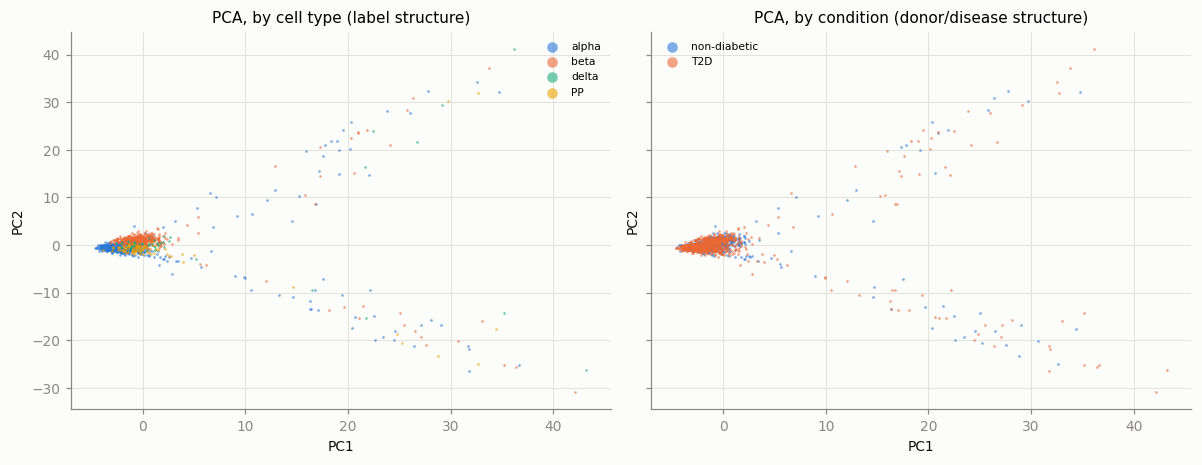

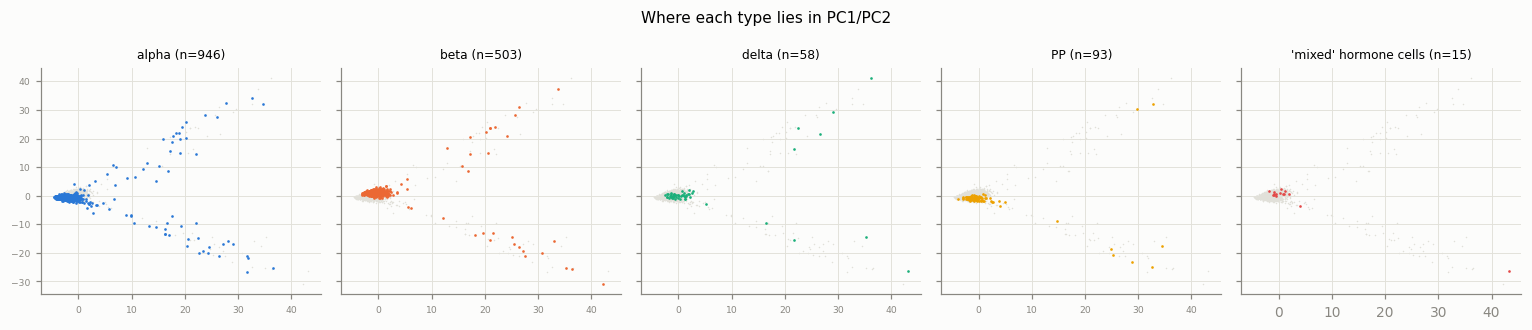

In [ ]:
rng = np.random.default_rng(SEED)
perm_b = rng.permutation(xin.n_obs)        # random draw order so no group is always painted on top
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
scatter_groups(axes[0], P_b, ct_b, TYPE_COLOR_B, "PCA, by cell type (label structure)", perm_b)
scatter_groups(axes[1], P_b, cond_b, COND_COLOR, "PCA, by condition (donor/disease structure)", perm_b)
fig.tight_layout(); plt.show()

# Per type, highlighted over the grey background of all cells, and the 'mixed' cells from B.6.
fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharex=True, sharey=True)
for ax, t in zip(axes, order_b):
    s = (ct_b == t).values
    ax.scatter(P_b[~s, 0], P_b[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P_b[s, 0], P_b[s, 1], s=3, color=TYPE_COLOR_B[t], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
axes[4].scatter(P_b[~mixed, 0], P_b[~mixed, 1], s=1, color=GRID, linewidths=0)
axes[4].scatter(P_b[mixed, 0], P_b[mixed, 1], s=3, color=PALETTE[7], linewidths=0)
axes[4].set_title(f"'mixed' hormone cells (n={mixed.sum()})", fontsize=8)
fig.suptitle("Where each type lies in PC1/PC2", fontsize=10)
fig.tight_layout(); plt.show()

In [ ]:
# What spreads the cells out along PC1/PC2? Top-loading genes, and who the cells outside the main cloud are.
for pc in load_b:
    print(f"{pc} top +: {load_b[pc].nlargest(8).index.tolist()}\n    top -: {load_b[pc].nsmallest(8).index.tolist()}")
outer_b = P_b[:, 0] > 5          # inspection threshold read off the plot: everything right of the dense cloud
display(pd.DataFrame({"outside main cloud": ct_b[outer_b].value_counts(), "all cells": counts_b})
        .loc[order_b].fillna(0).astype(int).T)
print(f"Cells outside the main cloud: {outer_b.sum()}  |  GEO cells minus cells in the paper (1,600 - 1,492): 108")
NON_ENDO = ["KRT19", "CFTR", "MMP7", "SPP1", "COL1A1", "COL1A2", "LUM", "SPARC", "PRSS1"]
display((pd.DataFrame({g: gene_vec(xin, g) > 0 for g in NON_ENDO}, index=xin.obs_names)
         .groupby(np.where(outer_b, "outside main cloud", "main cloud")).mean() * 100).round(0)
        .rename_axis("% cells with RPKM > 0"))
print("hormone-'mixed' cells (B.6) outside the main cloud:", int((mixed & outer_b).sum()), "of", int(mixed.sum()))
print("HVG gene types:", xin.var.loc[load_b.index, "gene_type"].value_counts().head(4).to_dict())

PC1 top +: ['IFITM3', 'SERPING1', 'LGALS3', 'BICC1', 'TFPI', 'SOX4', 'CFTR', 'MMP7']
    top -: ['TM4SF4', 'CRYBA2', 'APOH', 'LOXL4', 'F10', 'GPR119', 'SPTSSB', 'DEPP1']
PC2 top +: ['COL1A2', 'SPARC', 'BGN', 'COL1A1', 'COL3A1', 'COL6A3', 'LGALS1', 'TNFAIP6']
    top -: ['CFTR', 'LCN2', 'MMP7', 'PDZK1IP1', 'TSPAN8', 'KRT19', 'DEFB1', 'TACSTD2']


cell_type1,alpha,beta,delta,PP
outside main cloud,59,33,10,8
all cells,946,503,58,93


Cells outside the main cloud: 110  |  GEO cells minus cells in the paper (1,600 - 1,492): 108


,KRT19,CFTR,MMP7,SPP1,COL1A1,COL1A2,LUM,SPARC,PRSS1
% cells with RPKM > 0,,,,,,,,,
main cloud,11.0,12.0,8.0,33.0,11.0,8.0,3.0,9.0,23.0
outside main cloud,53.0,51.0,48.0,53.0,55.0,38.0,25.0,50.0,27.0


hormone-'mixed' cells (B.6) outside the main cloud: 1 of 15
HVG gene types: {'protein-coding': 1495, 'pseudo': 361, 'ncRNA': 77, 'unknown': 42}


**Structure observations**
* **Cell type dominates, donor and condition do not** (silhouette 0.27 by type, −0.12 by donor, 0.01 by condition;
  within alpha or beta cells the donor silhouette is negative). In this throw-away view, T2D and non-diabetic
  cells of the same type are not separated, so the condition shift is subtle at the level of global structure.
* **PC1 and PC2 are not driven by the four labelled types but by ~110 cells outside the main cloud.** PC1 loads on
  ductal genes (CFTR, MMP7, KRT19 on PC2−), PC2 on stellate/mesenchymal genes (COL1A1/2, SPARC, BGN). These cells
  carry a **ductal or stellate signature on top of their hormone label** (KRT19/CFTR/MMP7/COL1A1 detected in about
  50% of them vs about 10% in the main cloud). They are spread across all labels (59 alpha, 33 beta, 10 delta,
  8 PP).
* **Their number (110) is almost exactly the GEO-vs-paper difference (108).** The most plausible reading is that
  these are the cells the authors excluded as **contaminated (doublet-like endocrine + ductal/stellate)**, and that
  GEO kept them under their hormone label. This is a hypothesis: it should be checked against a curated version of
  the dataset that keeps the authors' exclusion flags before it is relied on. These are *not* the 15
  hormone-"mixed" cells of B.6 (only 1 overlaps); they are hormone-pure cells with an extra non-endocrine profile.
* Only 3% / 1.9% of the variance is on PC1/PC2 and 13.6% in 20 PCs, much less than Baron's 30%. The HVG set
  includes 361 pseudogenes, and the full-length data are noisier. Both point to doing the gene intersection and
  detection filter *before* HVG selection.

## B.8 Summary of the Xin inspection

| aspect | Xin (GSE81608) |
|---|---|
| cells × genes | 1,600 × 39,851 (37,987 with a current symbol) |
| technology | Fluidigm C1 + SMARTer, full-length, Nextera, HiSeq 2500 |
| values available | **RPKM only** (no counts in GEO) |
| labels | in the GEO SOFT file (`cell subtype`), no curated object needed |
| missing values | none |
| prior QC | yes (≥ 2,406 genes per cell) |
| MT genes | present (37, named without `MT-`); %MT high and type-dependent |
| classes | 4 endocrine (alpha 946, beta 503, PP 93, delta 58), imbalance 16× |
| batch structure | 18 donors (12 ND / 6 T2D), 24–306 cells each, composition uneven |
| notable | ~110 hormone-labelled cells with ductal/stellate signature (≈ the 108 cells not in the paper) |

## B.9 Proposed preprocessing for Xin (for discussion)
Same rules R1–R5 as in `data_preview.ipynb` Part 2; only what is specific to Xin is listed.

* **Step A — cell filtering (R4).** The shared rule (≥ 500 genes, ≥ 1,000 counts) removes nothing on genes, but its
  "counts" half **cannot be evaluated on RPKM**. Options: apply only the gene threshold to Xin, or define the
  shared rule on detected genes only. No %MT filter (B.4). **Decision needed on the ~110 contaminated-looking
  cells (B.7):** drop them (closest to the paper's 1,492 cells; needs a written, reproducible rule, e.g.
  co-detection of ductal/stellate markers, or the authors' flags from a curated object), or keep them as a
  realistic "impure" part of the query.
* **Step B — labels.** Rename `PP` → `gamma` to match Baron. All 4 classes have ≥ 20 cells. Lineage = endocrine for
  all.
* **Step C — genes (R2, R5).** Drop the `Entrez_*` names (no symbol), then intersect by symbol with the reference.
  18,199 genes are shared with Baron (see the final section). The intersection also removes the MT genes and most
  pseudogenes.
* **Step D — normalisation (R3), the main deviation.** Only RPKM is available. As for Camp, the closest we can get
  is to rescale each cell to a common total (10,000) and apply ln(1+x), which gives TPM-like values that still
  carry gene-length normalisation (unlike 3' UMI data). This must be documented as a deviation (§IV-E).
  *Alternative:* re-quantify the 1,600 SRA runs to get real counts, which is faithful but a large job.
* **Step E — HVG/scaling/PCA:** unchanged (fitted on the reference only).
* **Role in the study:** **query for E2 (A → B)**, a technology shift (inDrop 3' UMI → C1 full-length RPKM) whose
  query contains only 4 of Baron's 14 classes. The reverse **B → A** direction is a natural **E3** scenario (10 of
  Baron's types are unseen by an Xin reference). Within Xin, **non-diabetic → T2D** is an extra condition-shift
  scenario.

---
# Dataset C — Muraro et al. (GSE85241, human pancreas, CEL-seq2)

## C.0 What is in the SOFT file, and conversion
The SOFT file was copied (not moved) from `~/Downloads/proj_data/` to `data/raw/muraro_GSE85241/`.

In [ ]:
gse_c = GEOparse.get_GEO(filepath=str(MUR_SOFT))
print("GEO accession:", gse_c.name, "|", gse_c.metadata["title"][0])
print("Platforms:", list(gse_c.gpls), "| number of samples (GSM):", len(gse_c.gsms))
print("Series supplementary files:", *gse_c.metadata["supplementary_file"], sep="\n  ")
meta_c = soft_samples(gse_c)
print("\nGSM tables with rows:", int((meta_c.table_rows > 0).sum()), "| GSM supplementary files:",
      meta_c.supplementary_file.value_counts().to_dict())
print("Characteristic keys:", [c for c in meta_c.columns if c not in
      ("title", "description", "platform", "source", "table_rows", "supplementary_file")])
meta_c.head(3)

GEO accession: GSE85241 | A single-cell transcriptome atlas of the human pancreas [CEL-seq2]
Platforms: ['GPL18573'] | number of samples (GSM): 32
Series supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE85nnn/GSE85241/suppl/GSE85241_cel-seq_barcodes.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE85nnn/GSE85241/suppl/GSE85241_cellsystems_dataset_4donors_updated.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE85nnn/GSE85241/suppl/GSE85241_readme_demultiplexing_Cel-seq_data.pdf.gz

GSM tables with rows: 0 | GSM supplementary files: {'NONE': 32}
Characteristic keys: ['tissue']


,title,description,platform,source,table_rows,supplementary_file,tissue
GSM2262792,"Donor D28, live sorted cells, library 1",D28-1,GPL18573,human pancreas,0,NONE,pancreas
GSM2262793,"Donor D28, live sorted cells, library 2",D28-2,GPL18573,human pancreas,0,NONE,pancreas
GSM2262794,"Donor D28, live sorted cells, library 3",D28-3,GPL18573,human pancreas,0,NONE,pancreas


**What the SOFT file contains.** Even less than Xin: **32 GSMs = 4 donors (D28–D31) × 8 sequencing libraries**,
each library pooling 96 cells (CEL-seq2 barcodes). The only characteristic is `tissue: pancreas`, all GSM tables are
empty and there are no GSM supplementary files. There is **no per-cell information, and in particular no cell-type
labels**. The useful parts are the library ↔ donor mapping and the processing description (bwa on RefSeq hg19,
isoforms merged per gene, **4-bp UMI**). Platform GPL18573 = Illumina NextSeq 500.

The series supplementary files are a per-gene × per-well transcript table
(`GSE85241_cellsystems_dataset_4donors_updated.csv.gz`, 17 MB), the table of the 96 cell barcodes, and a PDF
readme on demultiplexing. The first two were downloaded from the GEO FTP site into `data/raw/muraro_GSE85241/`;
the PDF was not needed. Columns of the table are `<library>_<well>` (e.g. `D28-1_17`), and rows are
`<symbol>__<chromosome>`.

In [ ]:
UMI_LEN = 4                         # 4-bp UMI (SOFT data_processing) -> 4^4 = 256 distinct UMIs per gene and cell
K_UMI = 4 ** UMI_LEN

def build_muraro():
    """GEO transcript table (genes x wells) + SOFT library info + barcode table -> AnnData (wells x genes)."""
    tab = pd.read_csv(MUR_CSV, sep="\t", index_col=0)                        # 19,140 genes x 3,072 wells
    print("Transcript table (genes x wells):", tab.shape)
    var = pd.DataFrame(index=tab.index.astype(str))
    parts = var.index.str.partition("__")
    var["symbol"], var["chromosome"] = parts.get_level_values(0), parts.get_level_values(2)
    var["is_ercc"] = var["symbol"].str.startswith("ERCC-")
    var.loc[var.is_ercc, "chromosome"] = "spike-in"
    var.index.name = "gene_id"

    obs = pd.DataFrame(index=tab.columns.astype(str)); obs.index.name = "cell_id"
    obs["library"] = obs.index.str.split("_").str[0]                          # e.g. D28-1
    obs["donor"] = obs["library"].str.split("-").str[0]                       # D28 ... D31
    obs["well"] = obs.index.str.split("_").str[1].astype(int)                 # 1..96 = CEL-seq2 cell barcode index
    lib2gsm = pd.Series(meta_c.index, index=meta_c["description"])
    obs["gsm"] = obs["library"].map(lib2gsm)
    bc = pd.read_csv(MUR_BC, sep="\t", header=None, names=["well", "barcode"]).set_index("well")["barcode"]
    obs["barcode"] = obs["well"].map(bc)
    assert obs.gsm.notna().all() and obs.barcode.notna().all()
    # Author labels: NaN = well removed by the authors' QC (946 of 3,072), "unclear" = kept but unassigned.
    lab = pd.read_csv(MUR_LABELS, index_col="cell_id")
    assert set(lab.index) == set(obs.index), "label table and GEO wells do not match 1:1"
    lab = lab.loc[obs.index]
    assert (lab["donor"] == obs["donor"]).all(), "donor mismatch between label table and GEO"
    obs["cell_type1"] = lab["label"]
    obs["author_qc_pass"] = obs["cell_type1"].notna()

    T = sp.csr_matrix(tab.values.T, dtype="float32")
    assert np.allclose(np.asarray(T.sum(1)).ravel(), tab.sum(axis=0).values, rtol=1e-4), "conversion mismatch"
    print("Row sums of X match the GEO table column sums -> conversion is lossless (float32)")
    # The deposited values are UMI-saturation-corrected transcript estimates  t = -K ln(1 - u/K)  (Grün et al. 2014).
    # Inverting gives the observed number of distinct UMIs u, which must be an integer if K is right.
    U = T.copy(); U.data = (K_UMI * (1 - np.exp(-U.data.astype("float64") / K_UMI))).astype("float32")
    frac_int = np.mean(np.isclose(U.data, np.round(U.data), atol=1e-3))
    print(f"Back-transform with K = {K_UMI}: fraction of non-zero entries that become integers = {frac_int:.4f}")
    U.data = np.round(U.data)
    a = ad.AnnData(X=T, obs=obs, var=var, layers={"transcripts": T.copy(), "umi": U})
    a.uns["X_source_assay"] = "transcripts"
    a.uns["source_files"] = [str(MUR_SOFT), str(MUR_CSV), str(MUR_BC), str(MUR_LABELS)]
    a.write_h5ad(MURARO_H5, compression="gzip")
    print(f"-> {MURARO_H5}: {a.n_obs} wells x {a.n_vars} features")
    return a

mur = build_muraro()

Transcript table (genes x wells): (19140, 3072)


Row sums of X match the GEO table column sums -> conversion is lossless (float32)


Back-transform with K = 256: fraction of non-zero entries that become integers = 0.9999


-> /home/professor/cell-type-annotaion-benchmark/data/interim/muraro_human.h5ad: 3072 wells x 19140 features


## C.1 Overview of the Muraro (GSE85241) object

In [ ]:
print(mur)
print("\nX is assay:", mur.uns["X_source_assay"], "| dtype:", mur.X.dtype, "| sparse:", sp.issparse(mur.X))
print(f"Sparsity (fraction of zeros): {1 - mur.X.nnz / np.prod(mur.shape):.3f}")
print("Most frequent non-zero values:", pd.Series(mur.X.data).round(4).value_counts().head(4).to_dict())
print("Largest value:", round(float(mur.X.max()), 1), "transcripts =", int(mur.layers["umi"].max()), f"UMIs (ceiling {K_UMI})")
print("Wells per donor:", mur.obs.donor.value_counts().sort_index().to_dict(), "| libraries:", mur.obs.library.nunique())
mur.obs.head(3)

AnnData object with n_obs × n_vars = 3072 × 19140
    obs: 'library', 'donor', 'well', 'gsm', 'barcode'
    var: 'symbol', 'chromosome', 'is_ercc'
    uns: 'X_source_assay', 'source_files'
    layers: 'transcripts', 'umi', None (.X)

X is assay: transcripts | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.788
Most frequent non-zero values: {1.0019999742507935: 5663159, 2.0078999996185303: 2493916, 3.017699956893921: 1321783, 4.031599998474121: 780289}
Largest value: 1597.0 transcripts = 256 UMIs (ceiling 256)
Wells per donor: {'D28': 768, 'D29': 768, 'D30': 768, 'D31': 768} | libraries: 32


,library,donor,well,gsm,barcode
cell_id,,,,,
D28-1_1,D28-1,D28,1,GSM2262792,CATCACGC
D28-1_2,D28-1,D28,2,GSM2262792,GTCGTCGC
D28-1_3,D28-1,D28,3,GSM2262792,ACGACCGC


**What we have:** 3,072 wells × 19,140 features (19,059 genes + 81 ERCC spike-ins), 768 wells per donor. About
79% of entries are zero.

* **The values are not integers but are count-like.** The smallest value is 1.00196, then 2.0079, 3.0177, and so on.
  These are UMI counts corrected for UMI saturation, *t = −K·ln(1 − u/K)*. With *K* = 4⁴ = 256 (the 4-bp UMI from
  the SOFT file), inverting the formula turns **99.99% of non-zero entries back into integers**, which confirms
  the model and gives the observed UMI counts (`layers['umi']`). The few values that do not become integers are
  the saturated ones: the largest entry, 1,597 "transcripts", corresponds to 256 = *K* UMIs, i.e. every UMI was
  seen.
* `X` = the deposited, saturation-corrected `transcripts` (what the authors and downstream benchmarks use). The raw
  UMI counts are kept side by side as in `build_h5ad.py`.
* **This is the only one of the three pancreas datasets whose deposited values support the proposal's
  normalisation exactly** (library-size normalisation + log1p on counts).

**Where the expression values live.** As for Xin: `mur.X` is the cells × genes matrix (for Muraro: saturation-corrected UMI counts, hence non-integer), its columns are
named by `mur.var_names`, and `mur.obs` / `mur.var` only describe its rows / columns. One difference: Muraro's gene names carry the chromosome (`INS__chr11`), so the plain symbol is looked up in `mur.var['symbol']`. One example cell per type
against the marker genes:

In [ ]:
# Where the expression values live: mur.X is the cells x genes matrix; its rows are named by mur.obs_names (cells)
# and its columns by mur.var_names (genes). mur.obs / mur.var describe those rows / columns and hold no expression.
print("X:", type(mur.X).__name__, mur.X.shape, "| holds:", mur.uns["X_source_assay"],
      "| other versions in layers:", [k for k in mur.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(mur.var_names[:5]), "...")
print(f"Stored non-zero values: {mur.X.nnz:,} of {np.prod(mur.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['alpha', 'beta', 'delta', 'pp', 'acinar', 'duct']
ex_genes = ['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19']
ex_cells = [mur.obs_names[mur.obs["cell_type1"] == t][0] for t in ex_types]
ex_cols = [mur.var_names[mur.var["symbol"] == g][0] for g in ex_genes]   # var_names are "SYMBOL__chrN"
ex_window = mur[ex_cells, ex_cols].to_df().set_axis(ex_genes, axis=1)
ex_window.insert(0, "cell_type1", mur.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (3072, 19140) | holds: transcripts | other versions in layers: ['transcripts', 'umi']
Gene names = column names of X (var_names): ['A1BG-AS1__chr19', 'A1BG__chr19', 'A1CF__chr10', 'A2M-AS1__chr12', 'A2ML1__chr12'] ...
Stored non-zero values: 12,442,034 of 58,798,080 entries


,cell_type1,GCG,INS,SST,PPY,PRSS1,KRT19
cell_id,,,,,,,
D28-1_1,alpha,1597.011108,0.000000,130.105560,8.127666,1.001958,0.000000
D28-1_4,beta,84.541870,112.443382,118.725906,6.071431,4.031579,0.000000
D28-1_3,delta,77.678192,0.000000,1597.011108,5.049473,2.007854,1.001958
D28-1_76,pp,70.993736,3.017717,73.646614,595.533203,1.001958,0.000000
D28-1_37,acinar,138.555176,1.001958,193.967545,6.071431,54.389416,0.000000
D28-1_13,duct,61.919369,0.000000,81.774277,7.097484,2.007854,4.031579


## C.2 Data integrity and missing values
Same checklist. Here the matrix also contains **ERCC spike-ins** and every well of every plate, including empty or
failed wells, so the "zero total" and spike-in lines matter.

In [ ]:
display(integrity_checks(mur, integer_expected=False))
U_c = mur.layers["umi"]
print("non-integer values in the back-transformed 'umi' layer:", int((U_c.data != np.round(U_c.data)).sum()))
constant_cols = [c for c in mur.obs.columns if mur.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
dup_sym = mur.var[mur.var.symbol.duplicated(keep=False)].sort_values("symbol")
print(f"\nGene symbols occurring twice: {dup_sym.symbol.nunique()} (chromosomes: {dup_sym.chromosome.astype(str).value_counts().to_dict()})")
print(list(dup_sym.symbol.unique()))

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,12442034,n/a (not counts)
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,0,-


non-integer values in the back-transformed 'umi' layer: 0
0 constant obs columns (no information): []

Gene symbols occurring twice: 13 (chromosomes: {'chrX': 9, 'chrY': 8, 'chr5': 3, 'chr1': 3, 'chr10': 1, 'chr6': 1, 'chr8': 1})
['AKAP17A', 'ASMTL-AS1', 'CD99', 'CSF2RA', 'DHRSX', 'FAM45B', 'LOC100132062', 'LOC100132287', 'LOC100133331', 'PLCXD1', 'RNF5P1', 'SLC25A6', 'ZBED1']


In [ ]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names_c = mur.var["symbol"]
ercc_c = mur.var["is_ercc"].values
print("genes on chrM:          ", int((mur.var.chromosome == "chrM").sum()), "| names starting 'MT-':", int(names_c.str.startswith("MT-").sum()))
print("RPL/RPS ribosomal genes:", names_c.str.match(r"^RP[LS]\d").sum())
print("ERCC spike-ins:         ", int(ercc_c.sum()), list(names_c[ercc_c][:3]))
print("ERCC* real genes:       ", list(names_c[names_c.str.match(r"^ERCC\d")]))
print("chromosomes:", mur.var.chromosome.astype(str).value_counts().to_dict())

genes on chrM:           0 | names starting 'MT-': 0
RPL/RPS ribosomal genes: 122
ERCC spike-ins:          81 ['ERCC-00002', 'ERCC-00003', 'ERCC-00004']
ERCC* real genes:        ['ERCC1', 'ERCC2', 'ERCC3', 'ERCC4', 'ERCC5', 'ERCC6L2', 'ERCC6L', 'ERCC6', 'ERCC8']
chromosomes: {'chr1': 1914, 'chr19': 1326, 'chr2': 1251, 'chr17': 1096, 'chr3': 1084, 'chr11': 1084, 'chr6': 1023, 'chr12': 999, 'chr7': 938, 'chr5': 890, 'chr16': 808, 'chr10': 772, 'chr9': 750, 'chr4': 740, 'chrX': 675, 'chr8': 652, 'chr15': 629, 'chr14': 589, 'chr20': 509, 'chr22': 450, 'chr13': 360, 'chr18': 276, 'chr21': 208, 'spike-in': 81, 'chrY': 36}


**Integrity results**
* **No missing values**, no negative values, no duplicated well or feature IDs, no well with a zero total, and every
  gene is detected somewhere (the authors removed all-zero genes). The back-transformed UMI layer is fully integer.
* **13 gene symbols occur twice** with different chromosomes. Most are pseudo-autosomal genes listed once on chrX
  and once on chrY (CD99, SLC25A6, AKAP17A, …), plus a few LOC entries. The unique `symbol__chr` ID is kept as
  `var_names`; for symbol-based intersection the two copies must be summed or one dropped.
* **No mitochondrial genes:** reads were mapped to RefSeq nuclear gene models only, so there is no chrM and the
  standard %MT filter is again impossible (as for Baron). Nuclear `MTRNR2L*` genes do appear among the top genes
  in C.5; they are MT-RNR2-like loci that probably attract mitochondrial rRNA reads, but they are not a clean
  %MT measure.
* **Real ERCC spike-ins are present (81, `ERCC-000nn`)**, next to the real DNA-repair genes `ERCC1…ERCC8`. A
  prefix rule must use `ERCC-` and not `ERCC`. The spike-ins are useful for QC (C.4) and must be removed before
  any modelling.

## C.3 Cell-type labels: what are we classifying?
**GEO does not contain cell-type labels for GSE85241.** The SOFT file has only one characteristic (`tissue:
pancreas`) and the count table has no annotation row. The authors' labels (StemID clusters) are used in published
benchmarks via curated objects (e.g. the Hemberg-lab `muraro` SingleCellExperiment), which is the same source as the
Baron `.rds` used in `data_preview.ipynb`, but it is not an NCBI file and was **not** downloaded here.

To keep the rest of the inspection meaningful, wells are given a **provisional marker label**: after a minimal gate
that only removes obviously empty wells (≥ 1,000 non-ERCC transcripts, < 50% ERCC), each well gets the type whose
canonical marker(s) have the highest score (normalised log expression, scaled by that marker's 99th percentile),
or `unassigned` if the best score is weak or ambiguous. **This is not
ground truth and must not be used for evaluation.** Its only purpose is to read the QC, marker and PCA plots below.
The marker set used for the assignment is kept separate from the marker set used to check it in C.6.

In [ ]:
X_c = mur.X
tot_c = np.asarray(X_c[:, ~ercc_c].sum(1)).ravel()               # biological transcripts per well
pct_ercc_c = 100 * np.asarray(X_c[:, ercc_c].sum(1)).ravel() / np.maximum(np.asarray(X_c.sum(1)).ravel(), 1e-9)
GATE_C = (tot_c >= 1000) & (pct_ercc_c < 50)
print("Wells per library (8 per donor, 96 wells each):")
display(pd.crosstab(mur.obs.donor, mur.obs.library.str.split("-").str[1], margins=True))
print(f"Wells passing the minimal inspection gate: {GATE_C.sum()} of {mur.n_obs}")

ASSIGN_MARKERS = {   # used to assign; C.6 checks with a different set
    "alpha": ["GCG"], "beta": ["INS"], "delta": ["SST"], "pp": ["PPY"], "epsilon": ["GHRL"],
    "acinar": ["PRSS1", "CPA1", "CTRB2"], "ductal": ["KRT19", "SPP1"],
    "mesenchymal": ["COL1A1", "COL1A2"], "endothelial": ["PECAM1", "PLVAP"],
}
lognorm_c = X_c[:, ~ercc_c].multiply(1e4 / np.maximum(tot_c, 1)[:, None]).tocsr().log1p()
sym_bio = mur.var.symbol.values[~ercc_c]
score = pd.DataFrame({t: np.asarray(lognorm_c[:, np.isin(sym_bio, gs)].mean(1)).ravel()
                      for t, gs in ASSIGN_MARKERS.items()}, index=mur.obs_names)
# Raw log levels are not comparable between markers: GCG and SST are detected in ~100% of gated wells (ambient,
# see C.6), so a plain argmax calls far too many delta cells. Each score is therefore scaled by its own 99th
# percentile over the gated wells before taking the argmax.
scaled = score / score[GATE_C].quantile(0.99)
srt = np.sort(scaled.values, axis=1)
best = scaled.idxmax(axis=1)
MIN_SCALED, MAX_RATIO = 0.4, 0.85        # weak (< 40% of the marker's p99) or ambiguous (runner-up >= 85%) -> unassigned
confident = (srt[:, -1] >= MIN_SCALED) & (srt[:, -2] < MAX_RATIO * srt[:, -1])
print(f"Plain argmax of raw log scores would give: {score[GATE_C].idxmax(axis=1).value_counts().to_dict()}")
mur.obs["provisional_label"] = np.where(GATE_C & confident, best, "unassigned")
mur.obs["passes_gate"] = GATE_C
ct_c = mur.obs.loc[GATE_C, "provisional_label"].astype(str)
counts_c = ct_c.value_counts()
display(pd.DataFrame({"n_cells": counts_c, "fraction_%": (100 * counts_c / counts_c.sum()).round(2)}))
xt_c = pd.crosstab(ct_c, mur.obs.loc[GATE_C, "donor"]).loc[counts_c.index]
display(xt_c.style.background_gradient(cmap="Blues", axis=None))

Wells per library (8 per donor, 96 wells each):


library,1,2,3,4,5,6,7,8,All
donor,,,,,,,,,
D28,96,96,96,96,96,96,96,96,768
D29,96,96,96,96,96,96,96,96,768
D30,96,96,96,96,96,96,96,96,768
D31,96,96,96,96,96,96,96,96,768
All,384,384,384,384,384,384,384,384,3072


Wells passing the minimal inspection gate: 2461 of 3072


Plain argmax of raw log scores would give: {'alpha': 1048, 'delta': 628, 'beta': 292, 'acinar': 200, 'pp': 141, 'mesenchymal': 93, 'ductal': 53, 'epsilon': 3, 'endothelial': 3}


,n_cells,fraction_%
provisional_label,,
alpha,849,34.50
beta,389,15.81
unassigned,252,10.24
acinar,246,10.00
delta,240,9.75
ductal,202,8.21
pp,131,5.32
mesenchymal,101,4.10
endothelial,30,1.22


donor,D28,D29,D30,D31
provisional_label,,,,
alpha,92,246,286,225
beta,21,122,123,123
unassigned,66,69,63,54
acinar,90,7,38,111
delta,19,90,75,56
ductal,42,10,64,86
pp,14,70,6,41
mesenchymal,21,6,52,22
endothelial,7,4,8,11


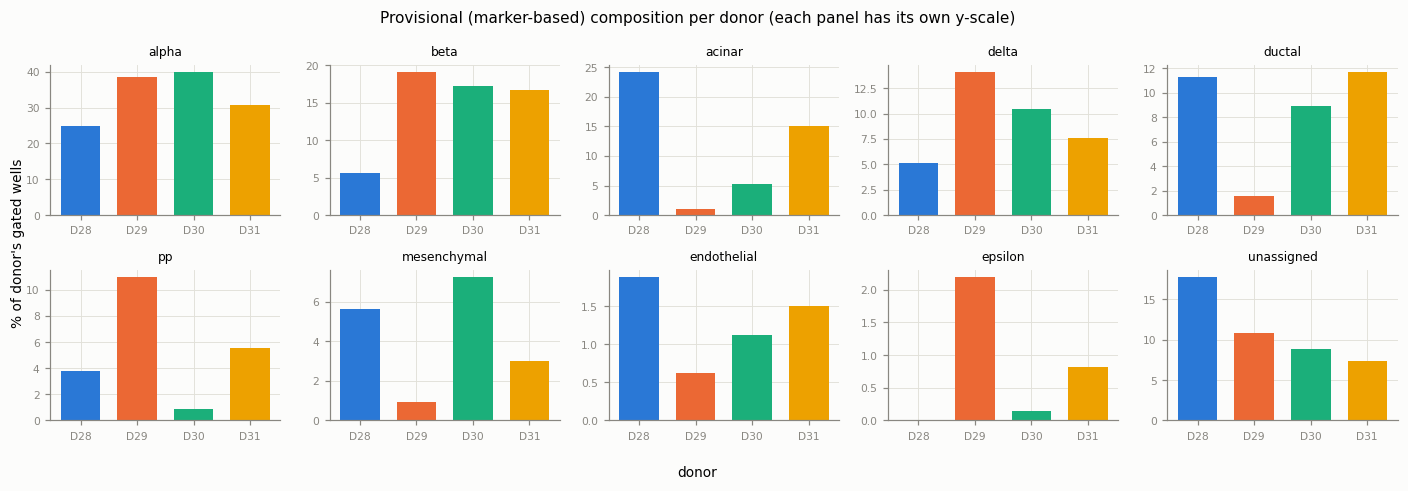

In [ ]:
# Provisional composition per donor (fractions), small multiples per class.
DONOR_COLOR_C = {d: PALETTE[i] for i, d in enumerate(sorted(mur.obs.donor.unique()))}
types_c = [t for t in counts_c.index if t != "unassigned"] + ["unassigned"]
frac_c = xt_c.div(xt_c.sum(axis=0), axis=1).loc[types_c] * 100
fig, axes = plt.subplots(2, 5, figsize=(13, 4.4))
for ax, t in zip(axes.ravel(), types_c):
    ax.bar(range(4), frac_c.loc[t].values, color=list(DONOR_COLOR_C.values()), width=0.7)
    ax.set_title(t, fontsize=8); ax.set_xticks(range(4), list(DONOR_COLOR_C)); ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(types_c):]:
    ax.axis("off")
fig.supxlabel("donor", fontsize=9); fig.supylabel("% of donor's gated wells", fontsize=9)
fig.suptitle("Provisional (marker-based) composition per donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()

**Label observations (provisional labels only)**
* The minimal gate keeps **2,461 of 3,072 wells**. Among them the provisional marker labels give alpha 849, beta
  389, acinar 246, delta 240, ductal 202, PP 131, mesenchymal 101, endothelial 30, epsilon 21 and **252
  unassigned** (weak or ambiguous marker signal). So, unlike Xin, **Muraro covers endocrine, exocrine and stromal
  lineages**, which makes it the dataset whose class set is closest to Baron's (no immune or Schwann cells, and
  stellate cells appear as one "mesenchymal" group).
* **Plain argmax on raw log levels calls 628 delta cells and only 53 ductal ones.** SST and GCG are present in almost
  every well (C.6), so without per-marker scaling the hormones win by level alone. This illustrates how strongly
  the ambient profile can bias any marker-based annotation in this dataset.
* **Composition differs strongly between donors:** D28 has the most acinar cells (24%) and few beta cells (6%),
  D29 has almost no exocrine or mesenchymal cells but the most delta, PP and epsilon cells. As in Baron, donor and
  composition are entangled.
* **These counts are not ground truth.** They are close in spirit, but not identical, to what the authors report,
  and the 21 "epsilon" cells in particular are doubtful (C.6). **For any evaluation the authors' labels must be
  obtained** (see C.9).

## C.4 Per-cell quality metrics: library size, detected genes, spike-in share
Unlike Baron and Xin, the deposited matrix has **not** been filtered: it holds all 3,072 wells, so this section
decides more than it did for Baron.

In [ ]:
qc_c = pd.DataFrame({
    "total_transcripts": tot_c,
    "n_genes": np.asarray((X_c[:, ~ercc_c] > 0).sum(1)).ravel(),
    "pct_ercc": pct_ercc_c,
    "top_gene_frac": np.asarray(X_c[:, ~ercc_c].max(1).todense()).ravel() / np.maximum(tot_c, 1e-9),
    "donor": mur.obs.donor.values, "library": mur.obs.library.values,
    "cell_type": mur.obs.provisional_label.values, "gate": GATE_C,
}, index=mur.obs_names)
qc_c["lineage"] = qc_c["cell_type"].map(LINEAGE)
display(qc_c[["total_transcripts", "n_genes", "pct_ercc", "top_gene_frac"]].describe().round(3).T)
thr = [0, 100, 500, 1000, 2000, 5000]
display(pd.DataFrame({"wells with >= t transcripts": [(tot_c >= t).sum() for t in thr],
                      "... and < 50% ERCC": [((tot_c >= t) & (pct_ercc_c < 50)).sum() for t in thr]}, index=thr).T)

,count,mean,std,min,25%,50%,75%,max
total_transcripts,3072.0,17508.061,17681.832,4.008,5661.918,14604.418,24104.246,260576.234
n_genes,3072.0,4032.777,2453.395,4.000,2407.500,4496.500,5806.750,12188.000
pct_ercc,3072.0,11.606,22.520,0.000,0.730,1.124,2.416,89.467
top_gene_frac,3072.0,0.077,0.062,0.006,0.032,0.063,0.102,0.636


,0,100,500,1000,2000,5000
wells with >= t transcripts,3072,3009,2529,2461,2417,2326
... and < 50% ERCC,2703,2685,2529,2461,2417,2326


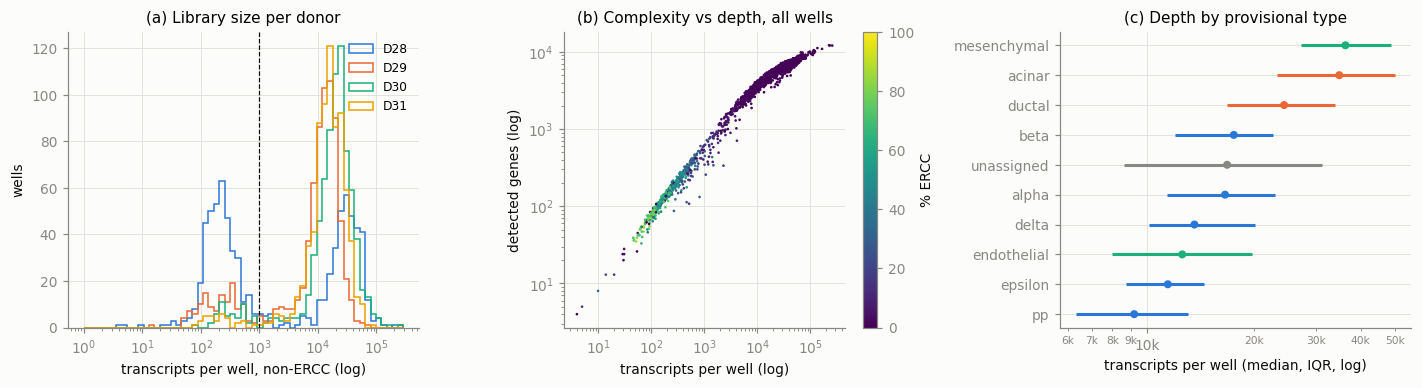

Gate pass rate per library (%): min 43.8 (D28-6), median 89.55 , max 97.9
Libraries below 60% pass rate: {'D28-1': 45.8, 'D28-2': 47.9, 'D28-3': 58.3, 'D28-4': 52.1, 'D28-5': 50.0, 'D28-6': 43.8, 'D28-7': 43.8, 'D28-8': 45.8}
Median transcripts per donor (gated): {'D28': 30842.0, 'D29': 13394.0, 'D30': 21359.0, 'D31': 16064.0}
Median top-gene fraction by provisional type (gated):
 cell_type
delta          0.101
alpha          0.085
pp             0.084
epsilon        0.056
acinar         0.039
unassigned     0.033
beta           0.030
ductal         0.023
mesenchymal    0.020
endothelial    0.020


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) library-size distribution per donor (log x-axis; includes the empty wells)
bins = np.logspace(0, np.log10(qc_c.total_transcripts.max() * 1.1), 60)
for d, c in DONOR_COLOR_C.items():
    axes[0].hist(qc_c.loc[qc_c.donor == d, "total_transcripts"].clip(lower=1), bins=bins, histtype="step", lw=1.5, color=c, label=d)
axes[0].axvline(1000, color=INK, lw=0.8, ls="--")
axes[0].set_xscale("log"); axes[0].set_xlabel("transcripts per well, non-ERCC (log)"); axes[0].set_ylabel("wells")
axes[0].set_title("(a) Library size per donor"); axes[0].legend(fontsize=8)
# (b) detected genes vs transcripts, coloured by %ERCC (all wells)
sca = axes[1].scatter(qc_c.total_transcripts.clip(lower=1), qc_c.n_genes.clip(lower=1), c=qc_c.pct_ercc, s=3,
                      cmap="viridis", vmin=0, vmax=100, linewidths=0)
fig.colorbar(sca, ax=axes[1], label="% ERCC")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("transcripts per well (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth, all wells")
# (c) library size per provisional type (gated wells, median and IQR)
q = qc_c[qc_c.gate]
g = q.groupby("cell_type")["total_transcripts"]
order = g.median().sort_values().index
med, q1, q3 = g.median()[order], g.quantile(.25)[order], g.quantile(.75)[order]
y = np.arange(len(order)); cols = [LINEAGE_COLOR[LINEAGE[t]] for t in order]
axes[2].hlines(y, q1, q3, color=cols, lw=2); axes[2].scatter(med, y, color=cols, s=18, zorder=3)
axes[2].set_yticks(y, order); axes[2].set_xscale("log"); axes[2].set_xlabel("transcripts per well (median, IQR, log)")
kfmt = plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k")
axes[2].xaxis.set_major_formatter(kfmt); axes[2].xaxis.set_minor_formatter(kfmt); axes[2].tick_params(axis="x", which="minor", labelsize=7)
axes[2].set_title("(c) Depth by provisional type")
fig.tight_layout(); plt.show()

lib_pass = qc_c.groupby("library").gate.mean().mul(100).round(1)
print("Gate pass rate per library (%): min", lib_pass.min(), f"({lib_pass.idxmin()}), median", lib_pass.median(),
      f", max {lib_pass.max()}")
print("Libraries below 60% pass rate:", lib_pass[lib_pass < 60].to_dict())
print("Median transcripts per donor (gated):", q.groupby("donor").total_transcripts.median().round(0).to_dict())
print("Median top-gene fraction by provisional type (gated):\n",
      q.groupby("cell_type").top_gene_frac.median().sort_values(ascending=False).round(3).to_string())

**QC observations**
* **This matrix is unfiltered, and QC is needed.** The library-size distribution (a) is bimodal: a main mode at
  about 10k–30k transcripts and a second group at about 100–500 transcripts whose wells consist mostly of spike-ins
  (b, yellow-green: up to 89% ERCC). Those are empty wells or failed lysis. In (b) the good wells form a tight
  depth-complexity band and the failed ones a separate tail, with a sparse region around 10³ transcripts.
* **The threshold is not critical:** anything between 500 and 2,000 transcripts keeps 2,529–2,417 wells, and
  ≥ 1,000 non-ERCC transcripts with < 50% ERCC keeps 2,461. (Benchmarks that use the authors' annotation have
  roughly 2,100 labelled cells; the difference would be the authors' stricter filtering and cluster curation.)
* **The failures are concentrated in donor D28:** all 8 D28 libraries have a pass rate of 44–58%, compared with
  a median of 90% overall. This is a plate/donor-level technical effect. Among the passing wells D28 is in fact the
  deepest (median 31k vs 13k–21k for the other donors), so the donors also differ in depth.
* **Depth depends on cell type**, as in Baron: mesenchymal and acinar wells have about 35k transcripts, endocrine
  cells 10k–17k, and PP cells the fewest. Library-size normalisation is needed for the same reason as before.
* **Top-gene dominance is much weaker than in Baron or Xin** (median 6% of a cell's transcripts in its top gene,
  vs 10% for Baron and 25% for Xin), consistent with UMI saturation capping the hormone genes at 256 UMIs.

## C.5 Gene-level behaviour: detection, top genes, mean–variance relationship
Computed on the gated wells and without ERCC spike-ins, so that empty wells do not inflate the "never detected"
counts.

In [ ]:
mur_g = mur[GATE_C, ~ercc_c].copy()
mur_g.var_names = mur_g.var["symbol"].astype(str)
mur_g.var_names_make_unique()      # 13 PAR genes (chrX/chrY copies) -> '-1' suffix, inspection only
print(f"Gated wells x biological genes: {mur_g.n_obs} x {mur_g.n_vars}")
n_expr_c, mean_c, var_c = gene_level(mur_g, "transcripts")

Gated wells x biological genes: 2461 x 19059


Genes detected in at most k cells:
  <=  0 cells:    10  (0.1%)
  <=  2 cells:  1347  (7.1%)
  <=  9 cells:  2762  (14.5%)
  <= 19 cells:  3695  (19.4%)
  <= 49 cells:  5043  (26.5%)

Top-15 genes by share of all transcripts (%):
GCG         2.53
MALAT1      2.41
MTRNR2L8    1.79
TTR         1.64
GNAS        1.12
SST         1.04
MTRNR2L1    0.78
REG1A       0.75
MTRNR2L2    0.62
EEF1A1      0.61
FTH1        0.51
REG3A       0.43
REG1B       0.42
B2M         0.37
RPL41       0.37


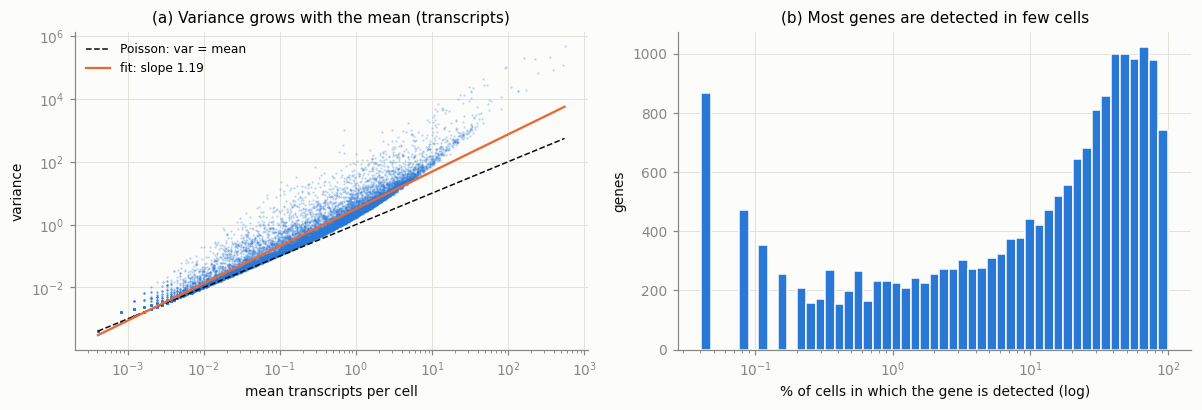

In [ ]:
slope_c = plot_gene_level(n_expr_c, mean_c, var_c, mur_g.n_obs, "transcripts")

**Gene-level observations** (2,461 gated wells, 19,059 biological genes)
* **The mean-variance slope is ≈ 1.19, close to Baron's 1.1.** These are UMI-based counts, and the familiar
  overdispersion at high means is still there, so `log1p` is justified as for Baron.
* **Top genes:** GCG (2.5% of all transcripts), MALAT1, nuclear MT-RNR2-like genes (MTRNR2L8/1/2), TTR, GNAS, SST,
  REG1A and other REG genes. **INS is not in the top 15** and is detected in only about 60% of wells. Compare INS
  at 5.3% of all UMIs in Baron. Part of this is the UMI ceiling (C.1), which compresses exactly the most highly
  expressed genes. INS is a key beta feature, so this is a concrete technology difference that a Baron-trained
  classifier would meet.
* **Feature sparsity is lower than in Baron or Xin:** only 10 genes are never detected in the gated wells, 14.5%
  are seen in fewer than 10 wells and 26.5% in fewer than 50 (Baron 25% / 35%). The authors had already removed
  undetected genes.

## C.6 Ambient RNA: do the (provisional) labels agree with markers, and how "clean" are the markers?
First the same panel as for Baron and Xin, then a **check panel of markers not used for the assignment**
(IRX2/ARX alpha, MAFA/HADH beta, HHEX delta, CHGA pan-endocrine, REG1A/CELA3A acinar, CFTR/SOX9 ductal,
PDGFRB/RGS5 stellate, ESAM/VWF endothelial). Agreement on the second panel is the real test of the provisional
labels.

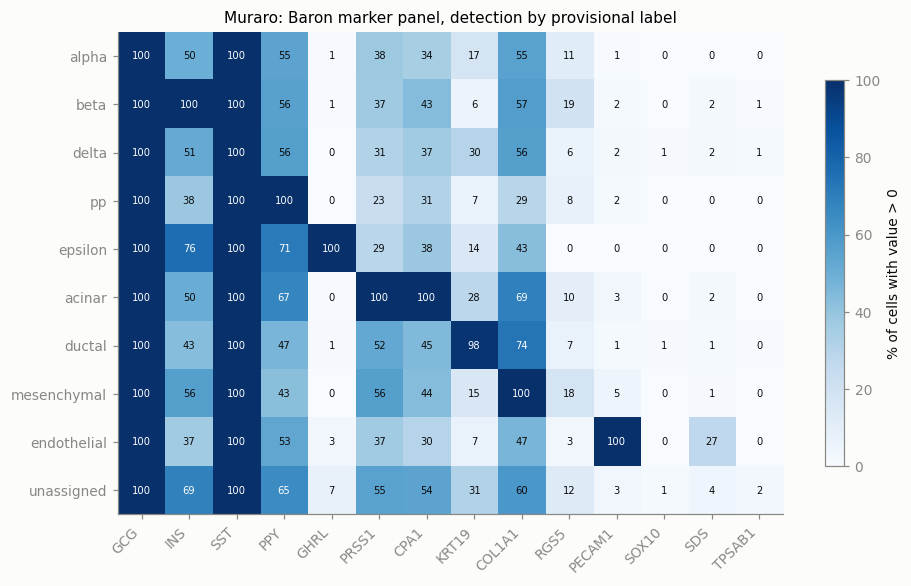

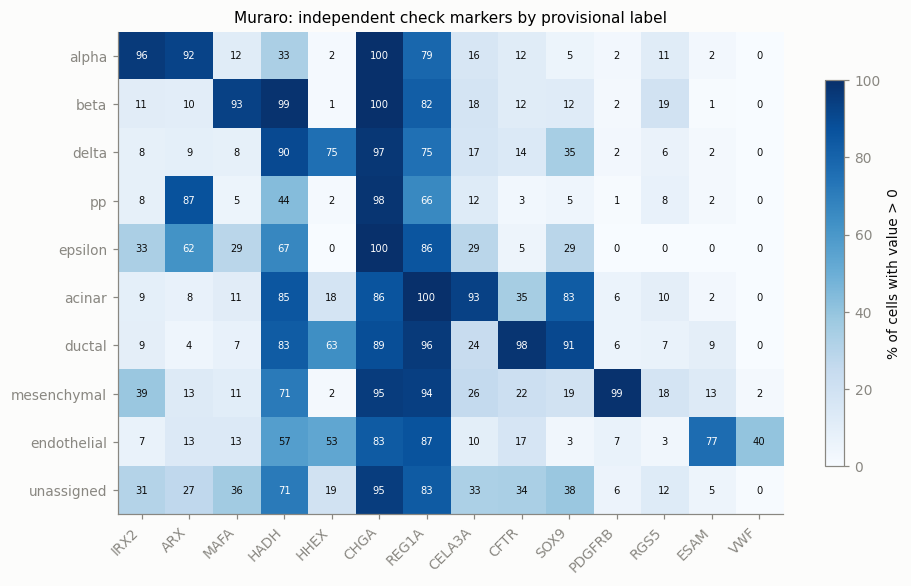

In [ ]:
order_c = [t for l in LINEAGE_ORDER for t in counts_c.index if LINEAGE[t] == l] + ["unassigned"]
lab_g = mur.obs.loc[GATE_C, "provisional_label"].values
detect_c = detection_heatmap(mur_g, list(MARKERS.values()), lab_g, order_c,
                             "Muraro: Baron marker panel, detection by provisional label")
CHECK = ["IRX2", "ARX", "MAFA", "HADH", "HHEX", "CHGA", "REG1A", "CELA3A", "CFTR", "SOX9", "PDGFRB", "RGS5", "ESAM", "VWF"]
check_c = detection_heatmap(mur_g, CHECK, lab_g, order_c,
                            "Muraro: independent check markers by provisional label")

**Marker observations**
* **The independent check markers support the provisional labels for the main types:** IRX2/ARX in 92–96% of alpha,
  MAFA in 93% of beta, HHEX in 75% of delta, CELA3A in 93% of acinar, CFTR/SOX9 in 98%/91% of ductal, PDGFRB in
  99% of mesenchymal and ESAM in 77% of endothelial wells. ARX in 87% of PP cells is again expected biology. The
  21 **epsilon** wells are not convincing (mixed IRX2/ARX/MAFA). Their score rests on a single gene (GHRL) scaled
  by its own 99th percentile, which favours rare markers, so most of them are probably misassigned.
* **Very strong ambient hormone signal:** GCG and SST are detected in **100% of wells of every type**, including
  acinar, ductal, mesenchymal and endothelial cells, and INS in 37–76% of non-beta wells. REG1A (acinar) is
  likewise detected in 66–100% of all types. These were FACS-sorted live cells, so this is ambient or carry-over
  RNA in the sorted suspension, and its profile (SST as ubiquitous as GCG, INS weaker) differs from both Baron and
  Xin. This is a third distinct ambient profile, which supports the shift descriptor for E6.
* `HHEX` is also detected in 63% of ductal and 53% of endothelial wells (HHEX is not delta-specific outside the
  islets), and `unassigned` wells show a mixed profile. They are a mix of doublets, low-depth cells and transitional
  acinar–ductal cells, and are the realistic "uncertain" query cells for the rejection analysis.

## C.7 Global structure: do cells group by type or by donor?
Same throw-away pipeline, on the gated wells without spike-ins (the deposited transcript estimates are treated as
counts).

In [ ]:
P_c, evr_c, load_c = throwaway_pca(mur_g)
lab_s = pd.Series(lab_g, index=mur_g.obs_names)
don_c = mur_g.obs["donor"].astype(str)
known = (lab_s != "unassigned").values
sil_type_c = silhouette_score(P_c[known, :20], lab_s[known], random_state=SEED)
sil_donor_c = silhouette_score(P_c[:, :20], don_c, random_state=SEED)
print(f"\nSilhouette by provisional type (assigned wells): {sil_type_c:.3f}   by donor: {sil_donor_c:.3f}")
within_c2 = {t: silhouette_score(P_c[(lab_s == t).values, :20], don_c[(lab_s == t).values])
             for t in ["alpha", "beta", "ductal", "acinar"]}
print("Silhouette by donor *within* one provisional type:", {k: round(v, 3) for k, v in within_c2.items()})
for pc in load_c:
    print(f"{pc} top +: {load_c[pc].nlargest(8).index.tolist()}\n    top -: {load_c[pc].nsmallest(8).index.tolist()}")

Explained variance, PC1..PC10 (%): [11.4  7.9  4.1  3.6  3.3  2.4  1.2  1.2  0.9  0.8]
Cumulative variance in 20 / 50 PCs: 42.3% / 49.3%



Silhouette by provisional type (assigned wells): 0.457   by donor: -0.070
Silhouette by donor *within* one provisional type: {'alpha': 0.02, 'beta': 0.044, 'ductal': -0.019, 'acinar': -0.055}
PC1 top +: ['IFITM3', 'ZFP36L1', 'REST', 'SOX4', 'LGALS3', 'PMEPA1', 'NOTCH2', 'CAV2']
    top -: ['PCSK1N', 'ABCC8', 'ISL1', 'MAFB', 'INSM1', 'GAD2', 'MIR7-3HG', 'CNIH2']
PC2 top +: ['SPARC', 'MRC2', 'NID1', 'LAMA4', 'PDGFRB', 'COL5A2', 'COL6A3', 'CDH11']
    top -: ['ELF3', 'TACSTD2', 'KRT8', 'KIAA1522', 'CFB', 'KRT18', 'ANXA4', 'KRT7']


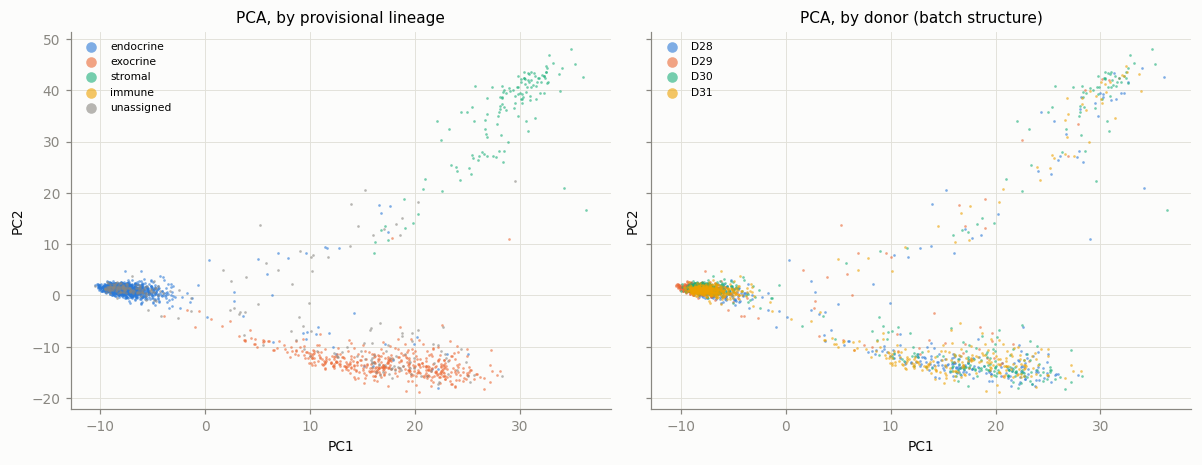

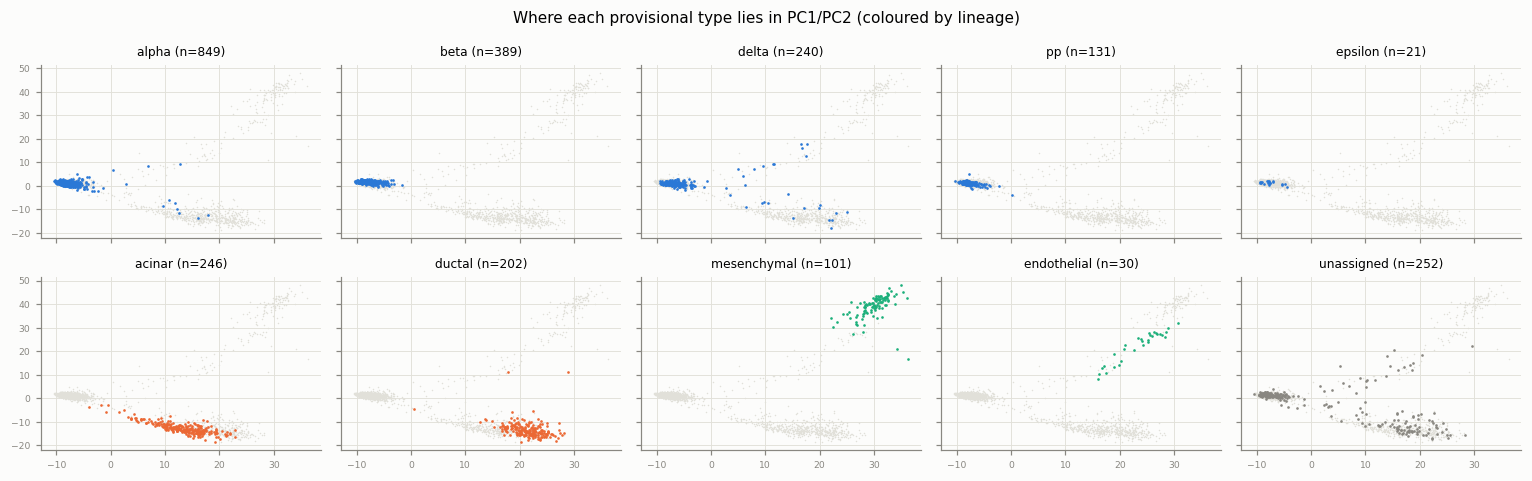

In [ ]:
rng = np.random.default_rng(SEED)
perm_c = rng.permutation(mur_g.n_obs)
lin_c = lab_s.map(LINEAGE).values
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
scatter_groups(axes[0], P_c, lin_c, LINEAGE_COLOR, "PCA, by provisional lineage", perm_c)
scatter_groups(axes[1], P_c, don_c, DONOR_COLOR_C, "PCA, by donor (batch structure)", perm_c)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), order_c):
    s = (lab_s == t).values
    ax.scatter(P_c[~s, 0], P_c[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P_c[s, 0], P_c[s, 1], s=3, color=LINEAGE_COLOR[LINEAGE[t]], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(order_c):]:
    ax.axis("off")
fig.suptitle("Where each provisional type lies in PC1/PC2 (coloured by lineage)", fontsize=10)
fig.tight_layout(); plt.show()

**Structure observations**
* **Very clear lineage structure:** PC1 (11.4%) separates endocrine (PCSK1N, ABCC8, ISL1, MAFB) from
  non-endocrine cells (IFITM3, SOX4, LGALS3), and PC2 (7.9%) separates the stromal arm (SPARC, PDGFRB, collagens)
  from the exocrine arm (KRT7/8/18, TACSTD2). 20 PCs hold 42% of the variance, more than Baron (30%) or Xin (14%):
  the CEL-seq2 data are less noisy in this view and the cell types are more diverse than in Xin.
* **Acinar and ductal cells form a continuum** along the exocrine arm rather than two separate clusters, and the
  endothelial cells lie between the exocrine and stromal arms. Within the endocrine blob the types overlap in
  PC1/PC2, as in Baron, and separate only in higher PCs.
* **The donor effect is small** (silhouette −0.07 overall, about 0 within types), even though D28 had a technical
  problem (C.4). The donor differences are mainly in composition (C.3), not in expression.
* The silhouette by provisional type (0.46) is **inflated by circularity**: the labels were derived from marker
  genes of the same data. It is not comparable with Baron's 0.31 (author labels).

## C.8 Summary of the Muraro inspection

| aspect | Muraro (GSE85241) |
|---|---|
| wells × features | 3,072 × 19,140 (19,059 genes + 81 ERCC); 2,461 wells pass a minimal gate |
| technology | automated CEL-seq2, 3' end, 4-bp UMI, FACS-sorted live cells, NextSeq 500 |
| values available | UMI-saturation-corrected counts (+ exact integer UMIs recovered) |
| labels | **none in GEO**; provisional marker labels for inspection only |
| missing values | none |
| prior QC | **no** (all wells deposited, incl. empty ones; D28 libraries ~50% failed) |
| MT genes | absent (no %MT QC); ERCC spike-ins present |
| classes (provisional) | ~9 types across endocrine, exocrine, stromal; 252 unassigned |
| batch structure | 4 donors × 8 libraries, composition uneven, small expression effect |
| notable | ubiquitous ambient GCG/SST; INS weak (UMI ceiling); closest class set to Baron |

## C.9 Proposed preprocessing for Muraro (for discussion)

* **Step A — cell filtering (R4).** Here filtering is required: ≥ 1,000 non-ERCC transcripts and < 50% ERCC
  (2,461 wells). The shared rule proposed for Baron (≥ 500 genes, ≥ 1,000 counts) gives essentially the same result
  and can be the common rule for all three datasets. Remove the ERCC spike-ins **after** QC.
* **Step B — labels (decision needed).** GEO has no labels. Options: **(B1, recommended)** obtain the authors'
  annotation from the curated Hemberg-lab `muraro` object, the same collection as `baron-human.rds`, and run it
  through `export_sce.R` / `build_h5ad.py`. Its cell IDs should match the `<library>_<well>` columns here (to be
  verified). **(B2)** use the paper's supplementary cluster assignments. **(B3)** use marker-based labels like the
  provisional ones above. B3 is not acceptable as ground truth, because the labels would be derived from the same
  markers that the classifiers use. After that: `pp` → `gamma`, and decide how `mesenchymal` maps onto Baron's
  `activated_stellate` / `quiescent_stellate` (a parent node in the hierarchy, which is exactly what HOE handles).
* **Step C — genes (R2, R5).** Use the symbol part of `symbol__chr`. Sum (or drop) the 13 duplicated PAR symbols,
  drop ERCC, then intersect (16,475 genes shared with Baron, see the final section).
* **Step D — normalisation (R3).** `normalize_total` (10,000) + `log1p` on the deposited transcripts, exactly as
  for Baron; no deviation. (`layers['umi']` is the alternative if raw integer UMIs are preferred.)
* **Role in the study:** the best **E2 query for A → C** (technology shift inDrop → CEL-seq2, with most classes
  shared), and a good reference for **C → A**, where Baron's immune and Schwann cells are unseen types for E3.

---
# Cross-dataset comparison: A (Baron), B (Xin), C (Muraro)
Analogous to §1.8–1.9 of `data_preview.ipynb`: gene overlap, label vocabularies, and one summary table. Baron is
loaded from the existing `data/interim/baron_human.h5ad` (read-only).

In [ ]:
baron = ad.read_h5ad(BARON_H5)
genes = {"A Baron": set(baron.var_names), "B Xin": set(xin.var.symbol[xin.var.mapped]),
         "C Muraro": set(mur.var.symbol[~mur.var.is_ercc])}
ov = pd.DataFrame({a: {b: len(genes[a] & genes[b]) for b in genes} for a in genes})
display(ov)
common = genes["A Baron"] & genes["B Xin"] & genes["C Muraro"]
print(f"Genes shared by all three: {len(common)}")
for g in ["INS", "GCG", "SST", "PPY", "GHRL", "PRSS1", "KRT19", "COL1A1", "PECAM1", "IRX2", "MAFA", "HHEX"]:
    assert g in common, g

labels = pd.DataFrame({
    "A Baron (author)": pd.Series(baron.obs.cell_type1.astype(str).value_counts()),
    "B Xin (author)": pd.Series(ct_b.value_counts()).rename(index={"PP": "gamma"}),
    "C Muraro (provisional)": pd.Series(counts_c).rename(index={"pp": "gamma"}),
}).fillna(0).astype(int)
labels["lineage"] = labels.index.map(LINEAGE).fillna("?")
display(labels.sort_values(["lineage", "A Baron (author)"], ascending=[True, False]))

,A Baron,B Xin,C Muraro
A Baron,20125,18199,16475
B Xin,18199,37987,16650
C Muraro,16475,16650,19046


Genes shared by all three: 15400


,A Baron (author),B Xin (author),C Muraro (provisional),lineage
beta,2525,503,389,endocrine
alpha,2326,946,849,endocrine
delta,601,58,240,endocrine
gamma,255,93,131,endocrine
epsilon,18,0,21,endocrine
ductal,1077,0,202,exocrine
acinar,958,0,246,exocrine
macrophage,55,0,0,immune
mast,25,0,0,immune
t_cell,7,0,0,immune


## Summary across datasets

| aspect | A: Baron (GSE84133 human) | B: Xin (GSE81608) | C: Muraro (GSE85241) |
|---|---|---|---|
| cells × genes | 8,569 × 20,125 | 1,600 × 39,851 | 3,072 wells (2,461 gated) × 19,059 + 81 ERCC |
| technology | inDrop, 3' UMI | Fluidigm C1 SMARTer, full-length | CEL-seq2, 3' UMI, FACS-sorted |
| values | raw UMI counts | **RPKM only** | saturation-corrected UMI counts |
| labels | author (curated `.rds`) | author (in GEO SOFT) | **none in GEO** (provisional only) |
| prior QC | yes | yes | **no** |
| MT genes | removed | present (no `MT-` prefix) | absent |
| classes | 14 (4 lineages) | 4 (endocrine only) | ~9 (3 lineages, provisional) |
| donors | 4 | 18 (12 ND / 6 T2D) | 4 (× 8 libraries) |
| ambient profile | INS everywhere | GCG everywhere, INS often | GCG + SST everywhere, INS weak |

**Gene overlap:** 18,199 genes are shared by Baron and Xin, 16,475 by Baron and Muraro, and **15,400 by all
three**, including every marker used above. The intersection is large enough that R2 (shared gene set) costs
little. **Label overlap:** after `PP`/`pp` → `gamma`, all four Xin types exist in Baron, and Muraro's types all
exist in Baron except `mesenchymal`, which corresponds to Baron's two stellate states (a parent node).

## Questions to agree on before preprocessing B and C
1. **Muraro labels:** fetch the curated Hemberg-lab `muraro` object (same source as Baron's `.rds`, recommended),
   or use the paper's supplementary assignments? Until then Dataset C can only be used unlabelled (e.g. as an
   open-set / rejection query).
2. **Xin contaminated-looking cells (~110):** drop them with a written marker rule (matching the paper's 1,492
   cells), or keep them as a realistic impure query?
3. **Xin RPKM:** accept "rescale to 10k + log1p" as a documented deviation from R3 (as proposed for Camp), or
   re-quantify the SRA reads to obtain counts?
4. **Common QC rule across A/B/C:** ≥ 500 detected genes for all three, plus ≥ 1,000 counts where counts exist
   (A, C), with no %MT filter anywhere. OK?
5. **E2 scenarios:** A → C as the main technology-shift test (most shared classes), A → B as the
   "query has a subset of classes" case, and B → A / C → A as unseen-type (E3) scenarios?